# 6 Wavelet-Based Feature Extraction for Machine Learning

## 6.3 Wavelet Selection for Feature 

### 6.3.2 Example: Wavelet Selection for ECG Signal

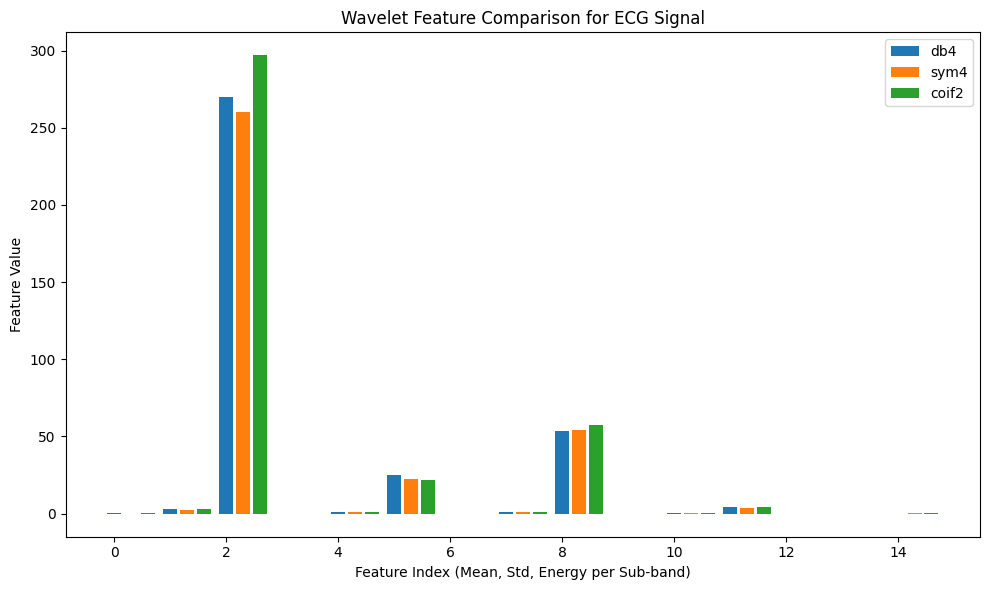

In [ ]:
import pywt
import numpy as np
import matplotlib.pyplot as plt

# Synthetic ECG-like signal
t = np.linspace(0, 1, 512)
signal = np.sin(2 * np.pi * 10 * t) + 0.5 * np.sin(2 * np.pi * 40 * t)

# Function to extract features
def wavelet_features(signal, wavelet, level=4):
    coeffs = pywt.wavedec(signal, wavelet, level=level)
    features = []
    for i, c in enumerate(coeffs):
        features.extend([np.mean(c), np.std(c), np.sum(c**2)])
    return features

# Compare wavelets
wavelets = ['db4', 'sym4', 'coif2']
features_dict = {w: wavelet_features(signal, w) for w in wavelets}

# Plot feature comparison
plt.figure(figsize=(10, 6))
for i, (wavelet, features) in enumerate(features_dict.items()):
    plt.bar(np.arange(len(features)) + i*0.3, features, width=0.25, label=wavelet)
plt.xlabel('Feature Index (Mean, Std, Energy per Sub-band)')
plt.ylabel('Feature Value')
plt.title('Wavelet Feature Comparison for ECG Signal')
plt.legend()
plt.tight_layout()
plt.savefig('./output/23.1_wavelet_feature_comparison_ecg.png')
plt.show()

## 6.4 Extracting Features from 1D Signals

### 6.4.1 Common Features from 1D Wavelets

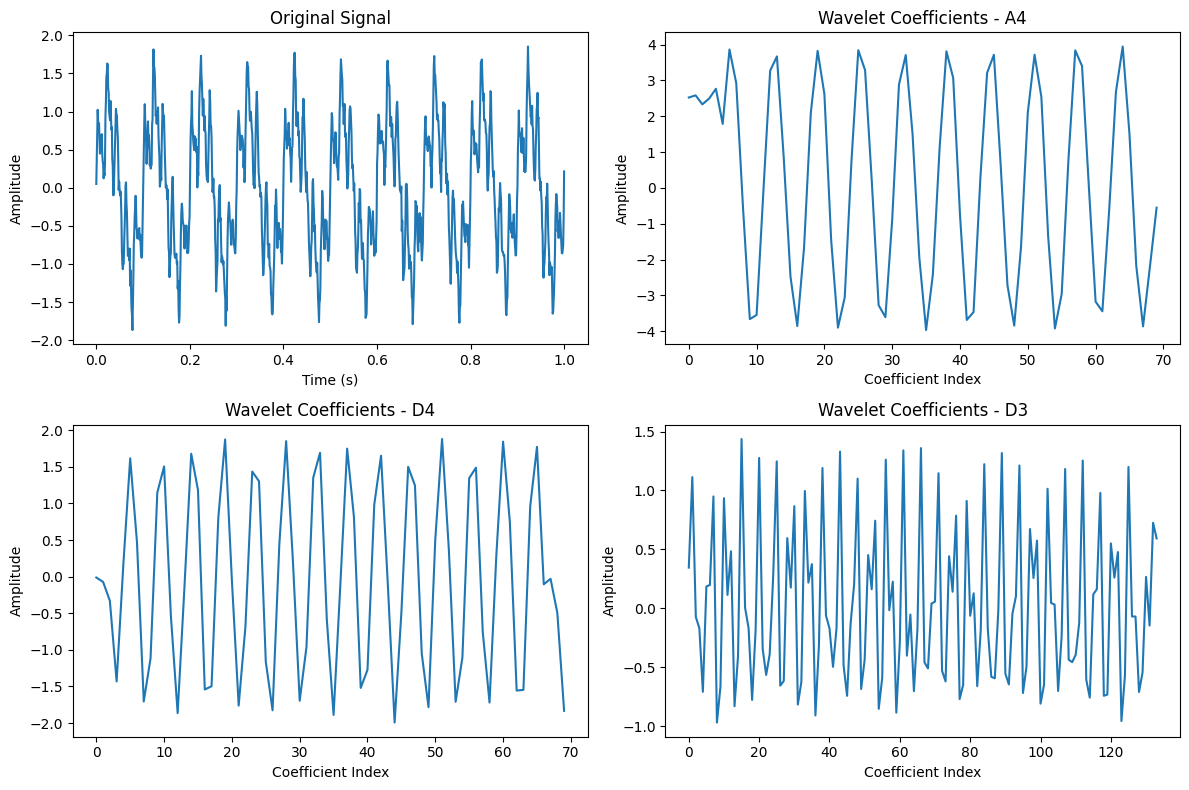

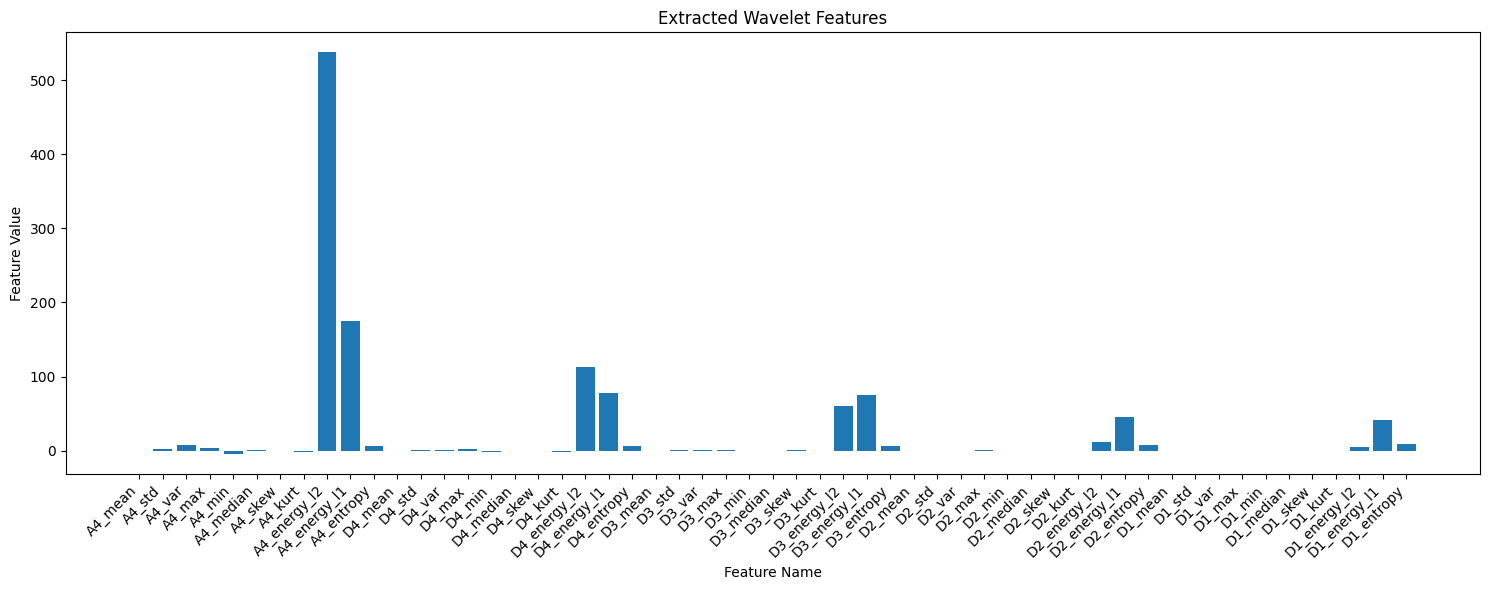

Extracted 55 features:
A4_mean: 0.1908
A4_std: 2.7639
A4_var: 7.6389
A4_max: 3.9445
A4_min: -3.9660
A4_median: 0.4452
A4_skew: -0.1433
A4_kurt: -1.4880
A4_energy_l2: 537.2707
A4_energy_l1: 174.9066
...


In [ ]:
import pywt
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

def comprehensive_wavelet_features(signal, wavelet='db4', level=4):
    """
    Extract comprehensive features from 1D signal using wavelet decomposition
    """
    # Perform wavelet decomposition
    coeffs = pywt.wavedec(signal, wavelet, level=level)
    
    features = []
    feature_names = []
    
    for i, c in enumerate(coeffs):
        level_name = f'A{level}' if i == 0 else f'D{level-i+1}'
        
        # Statistical features
        features.extend([
            np.mean(c),           # Mean
            np.std(c),            # Standard deviation
            np.var(c),            # Variance
            np.max(c),            # Maximum
            np.min(c),            # Minimum
            np.median(c),         # Median
            stats.skew(c),        # Skewness
            stats.kurtosis(c),    # Kurtosis
        ])
        
        # Energy features
        energy_l2 = np.sum(np.square(c))  # L2 energy
        energy_l1 = np.sum(np.abs(c))     # L1 energy
        features.extend([energy_l2, energy_l1])
        
        # Entropy
        # Normalize coefficients to create probability distribution
        c_norm = np.abs(c) / (np.sum(np.abs(c)) + 1e-12)
        entropy = -np.sum(c_norm * np.log2(c_norm + 1e-12))
        features.append(entropy)
        
        # Feature names for this level
        base_names = ['mean', 'std', 'var', 'max', 'min', 'median', 'skew', 'kurt', 'energy_l2', 'energy_l1', 'entropy']
        feature_names.extend([f'{level_name}_{name}' for name in base_names])
    
    return np.array(features), feature_names

# Example usage with synthetic signal
np.random.seed(42)
t = np.linspace(0, 1, 1024)
# Create a complex signal with different frequency components
signal = (np.sin(2*np.pi*10*t) + 0.5*np.sin(2*np.pi*50*t) + 
          0.3*np.sin(2*np.pi*100*t) + 0.1*np.random.normal(size=len(t)))

# Extract features
features, feature_names = comprehensive_wavelet_features(signal)

# Visualization
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Original signal
axes[0,0].plot(t, signal)
axes[0,0].set_title('Original Signal')
axes[0,0].set_xlabel('Time (s)')
axes[0,0].set_ylabel('Amplitude')

# Wavelet decomposition visualization
coeffs = pywt.wavedec(signal, 'db4', level=4)
for i, c in enumerate(coeffs):
    level_name = f'A4' if i == 0 else f'D{5-i}'
    if i < 3:  # Show first 3 levels
        row, col = (0,1) if i == 0 else (1, i-1)
        axes[row, col].plot(c)
        axes[row, col].set_title(f'Wavelet Coefficients - {level_name}')
        axes[row, col].set_xlabel('Coefficient Index')
        axes[row, col].set_ylabel('Amplitude')

plt.tight_layout()
plt.savefig('./output/wavelet_decomposition_visualization.png')
plt.show()

# Feature importance visualization
plt.figure(figsize=(15, 6))
plt.bar(range(len(features)), features)
plt.xticks(range(len(features)), feature_names, rotation=45, ha='right')
plt.title('Extracted Wavelet Features')
plt.xlabel('Feature Name')
plt.ylabel('Feature Value')
plt.tight_layout()
plt.savefig('./output/extracted_wavelet_features.png')
plt.show()

print(f"Extracted {len(features)} features:")
for i, (name, value) in enumerate(zip(feature_names[:10], features[:10])):
    print(f"{name}: {value:.4f}")
print("...")

### 6.4.2 Advanced 1D Feature Extraction

Let’s replace the middle subplot with a full cross-scale correlation matrix so the heatmap is meaningful.

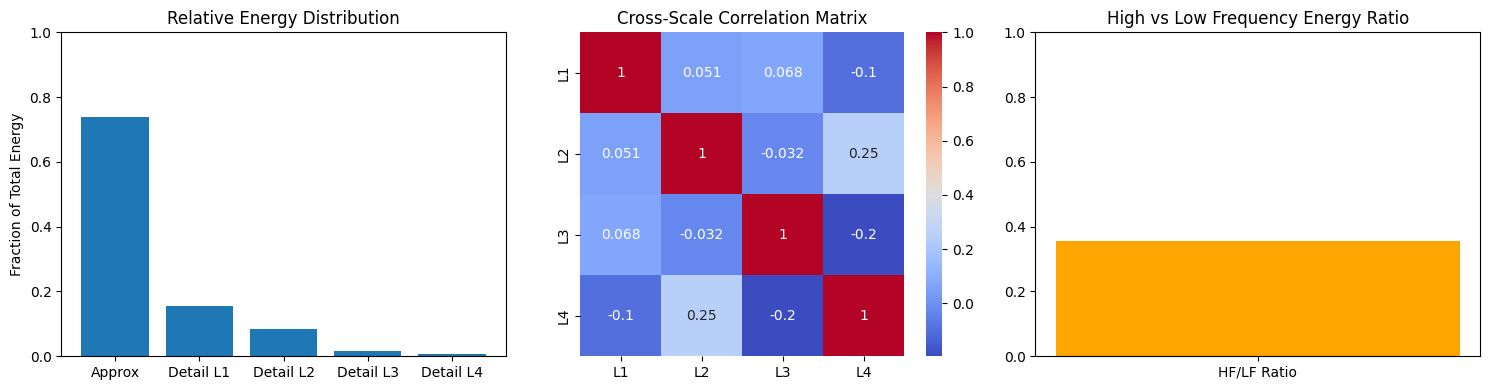

Advanced features: [0.73826557 0.15595733 0.08316727 0.01557828 0.00703154 0.35452612]


In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt
import seaborn as sns

def advanced_1d_features(signal, wavelet='db4', level=4, visualize=False):
    coeffs = pywt.wavedec(signal, wavelet, level=level)
    features = []
    
    # Relative energy distribution
    total_energy = sum(np.sum(np.square(c)) for c in coeffs)
    relative_energies = [np.sum(np.square(c))/total_energy for c in coeffs]
    features.extend(relative_energies)
    
    # Cross-scale correlation matrix (all detail levels)
    detail_coeffs = [c for c in coeffs[1:]]
    min_len = min(len(c) for c in detail_coeffs)
    aligned = np.array([c[:min_len] for c in detail_coeffs])  # align length
    corr_matrix = np.corrcoef(aligned)
    
    # Wavelet energy ratios
    approx_energy = np.sum(np.square(coeffs[0]))
    detail_energies = [np.sum(np.square(c)) for c in coeffs[1:]]
    total_detail_energy = sum(detail_energies)
    hf_lf_ratio = total_detail_energy / approx_energy if approx_energy > 0 else 0
    features.append(hf_lf_ratio)
    
    if visualize:
        fig, axs = plt.subplots(1, 3, figsize=(15, 4))
        
        # (1) Energy distribution
        labels = ['Approx'] + [f'Detail L{i}' for i in range(1, len(coeffs))]
        axs[0].bar(labels, relative_energies)
        axs[0].set_title("Relative Energy Distribution")
        axs[0].set_ylabel("Fraction of Total Energy")
        axs[0].set_ylim(0, 1)
        
        # (2) Cross-scale correlation heatmap
        sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", cbar=True,
                    xticklabels=[f"L{i}" for i in range(1, len(coeffs))],
                    yticklabels=[f"L{i}" for i in range(1, len(coeffs))],
                    ax=axs[1], square=True)
        axs[1].set_title("Cross-Scale Correlation Matrix")
        
        # (3) HF/LF ratio
        axs[2].bar(["HF/LF Ratio"], [hf_lf_ratio], color="orange")
        axs[2].set_ylim(0, max(1, hf_lf_ratio*1.2))
        axs[2].set_title("High vs Low Frequency Energy Ratio")
        
        plt.tight_layout()
        plt.savefig('./output/advanced_wavelet_features.png')
        plt.show()
    
    return np.array(features)

# Example usage
advanced_features = advanced_1d_features(signal, visualize=True)
print("Advanced features:", advanced_features)


## 6.5 2D Wavelet Features for Images

### 6.5.1 Texture and Spatial Features

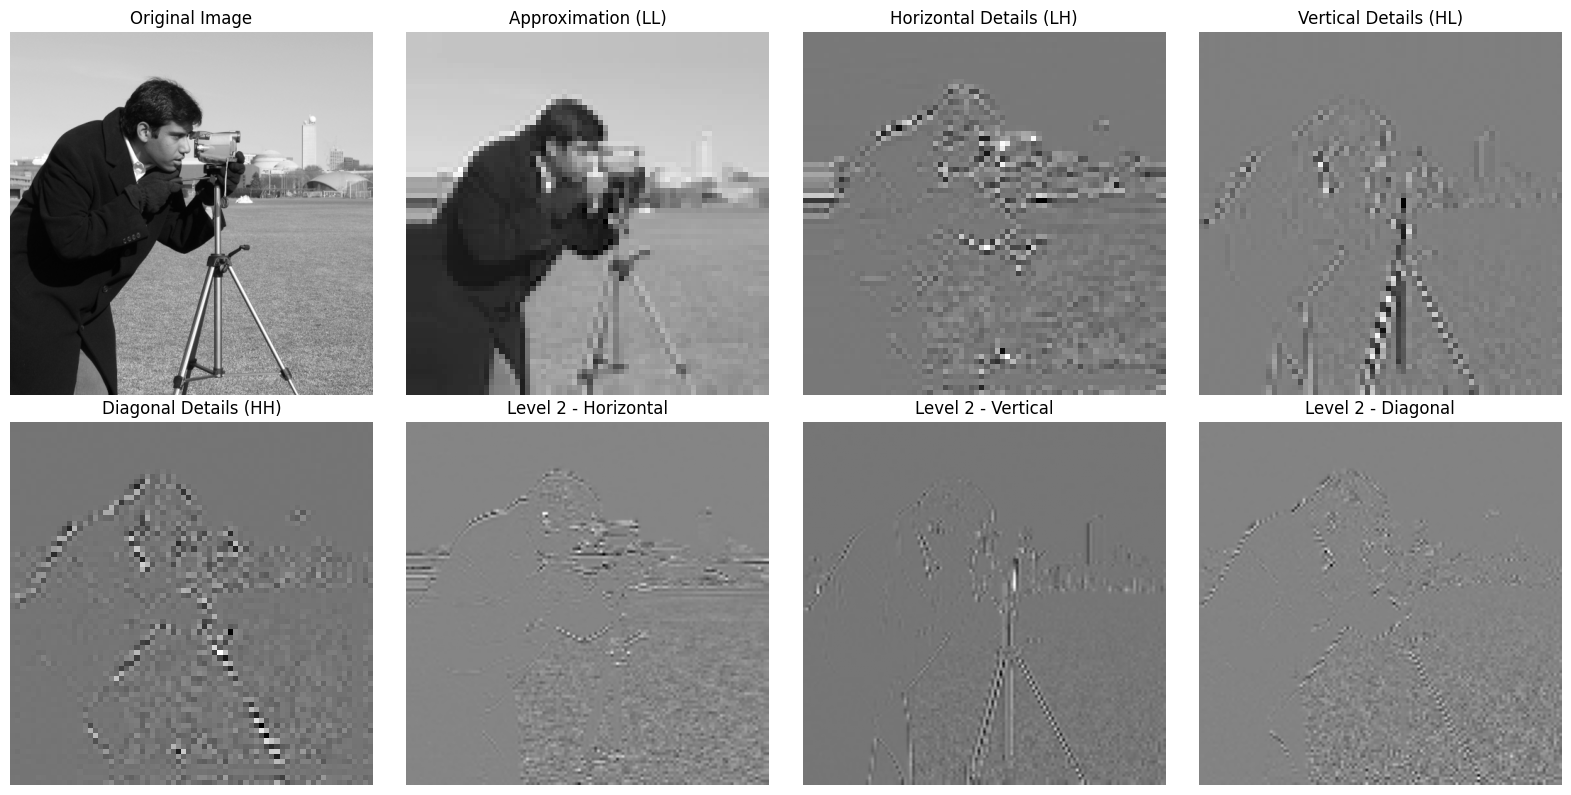

Extracted 78 2D wavelet features
Sample features:
LL_mean: 1061.3502
LL_std: 574.8437
LL_var: 330445.2895
LL_skew: -0.5871
LL_kurt: -1.1663
LL_energy: 7138856872.4779
L1_LH_mean: 1.1847
L1_LH_std: 45.4381
L1_LH_var: 2064.6176
L1_LH_skew: 0.5131


In [ ]:
import pywt
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data
from scipy import stats

def extract_2d_wavelet_features(image, wavelet='db4', level=3):
    """
    Extract comprehensive features from 2D image using wavelet decomposition
    """
    # Ensure image is grayscale
    if len(image.shape) == 3:
        image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    
    # Perform 2D wavelet decomposition
    coeffs = pywt.wavedec2(image, wavelet, level=level)
    
    features = []
    feature_names = []
    
    # Process approximation coefficients (LL)
    ll_coeffs = coeffs[0]
    ll_features = [
        np.mean(ll_coeffs), np.std(ll_coeffs), np.var(ll_coeffs),
        stats.skew(ll_coeffs.flatten()), stats.kurtosis(ll_coeffs.flatten()),
        np.sum(np.square(ll_coeffs))  # Energy
    ]
    features.extend(ll_features)
    feature_names.extend(['LL_mean', 'LL_std', 'LL_var', 'LL_skew', 'LL_kurt', 'LL_energy'])
    
    # Process detail coefficients for each level
    for i, (lh, hl, hh) in enumerate(coeffs[1:], 1):
        for orientation, coeff in [('LH', lh), ('HL', hl), ('HH', hh)]:
            # Statistical features
            coeff_features = [
                np.mean(coeff), np.std(coeff), np.var(coeff),
                stats.skew(coeff.flatten()), stats.kurtosis(coeff.flatten()),
                np.sum(np.square(coeff)),  # Energy
                np.sum(np.abs(coeff)),     # L1 norm
            ]
            features.extend(coeff_features)
            
            # Texture measures
            # Local binary pattern-like feature
            edges = np.sum(np.abs(coeff) > np.std(coeff))
            features.append(edges / coeff.size)  # Edge density
            
            names = [f'L{i}_{orientation}_mean', f'L{i}_{orientation}_std', f'L{i}_{orientation}_var',
                    f'L{i}_{orientation}_skew', f'L{i}_{orientation}_kurt', f'L{i}_{orientation}_energy',
                    f'L{i}_{orientation}_l1', f'L{i}_{orientation}_edge_density']
            feature_names.extend(names)
    
    return np.array(features), feature_names

# Load and process a sample image
image = data.camera()  # Use skimage's camera image
features_2d, names_2d = extract_2d_wavelet_features(image)

# Visualize 2D wavelet decomposition
coeffs_2d = pywt.wavedec2(image, 'db4', level=3)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()  # Flatten to 1D array for easy indexing

# Plot original image
axes[0].imshow(image, cmap='gray')
axes[0].set_title('Original Image')
axes[0].axis('off')

# Plot approximation (LL)
axes[1].imshow(coeffs_2d[0], cmap='gray')
axes[1].set_title('Approximation (LL)')
axes[1].axis('off')

# Plot first-level detail coefficients (LH, HL, HH)
details_1 = coeffs_2d[1]
titles = ['Horizontal Details (LH)', 'Vertical Details (HL)', 'Diagonal Details (HH)']
for i, (detail, title) in enumerate(zip(details_1, titles)):
    axes[i+2].imshow(detail, cmap='gray')
    axes[i+2].set_title(title)
    axes[i+2].axis('off')

# Plot second-level detail coefficients if exist
if len(coeffs_2d) > 2:
    details_2 = coeffs_2d[2]
    for i, detail in enumerate(details_2):
        axes[i+5].imshow(detail, cmap='gray')  # index 5,6,7
        axes[i+5].set_title(f'Level 2 - {titles[i].split()[0]}')
        axes[i+5].axis('off')

plt.tight_layout()
plt.savefig('./output/wavelet_decomposition_2d.png')
plt.show()

print(f"Extracted {len(features_2d)} 2D wavelet features")
print("Sample features:")
for i in range(min(10, len(features_2d))):
    print(f"{names_2d[i]}: {features_2d[i]:.4f}")

### 6.5.2 Multi-scale Texture Analysis

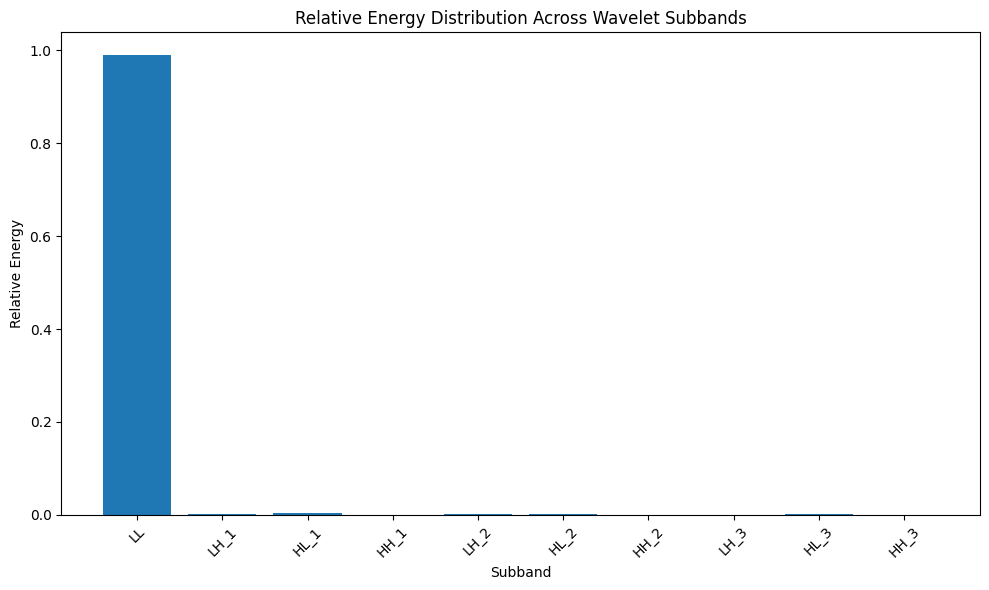

In [ ]:
def texture_energy_features(image, wavelet='db4', level=3):
    """
    Extract texture features based on energy distribution across sub-bands
    """
    coeffs = pywt.wavedec2(image, wavelet, level=level)
    
    # Calculate total energy
    total_energy = np.sum(np.square(coeffs[0]))
    for level_coeffs in coeffs[1:]:
        for subband in level_coeffs:
            total_energy += np.sum(np.square(subband))
    
    # Relative energy in each subband
    relative_energies = []
    
    # Approximation energy
    ll_energy = np.sum(np.square(coeffs[0])) / total_energy
    relative_energies.append(ll_energy)
    
    # Detail energies
    for level_coeffs in coeffs[1:]:
        for subband in level_coeffs:
            energy = np.sum(np.square(subband)) / total_energy
            relative_energies.append(energy)
    
    return np.array(relative_energies)

# Extract texture features
texture_features = texture_energy_features(image)

# Visualize energy distribution
plt.figure(figsize=(10, 6))
labels = ['LL'] + [f'{orient}_{i+1}' for i in range(3) for orient in ['LH', 'HL', 'HH']]
plt.bar(labels, texture_features)
plt.title('Relative Energy Distribution Across Wavelet Subbands')
plt.xlabel('Subband')
plt.ylabel('Relative Energy')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('./output/texture_energy_distribution.png')
plt.show()

## 6.6 Multi-dimensional Wavelet Features

### 6.6.1 3D Wavelet Transform

Extracted 216 3D wavelet features


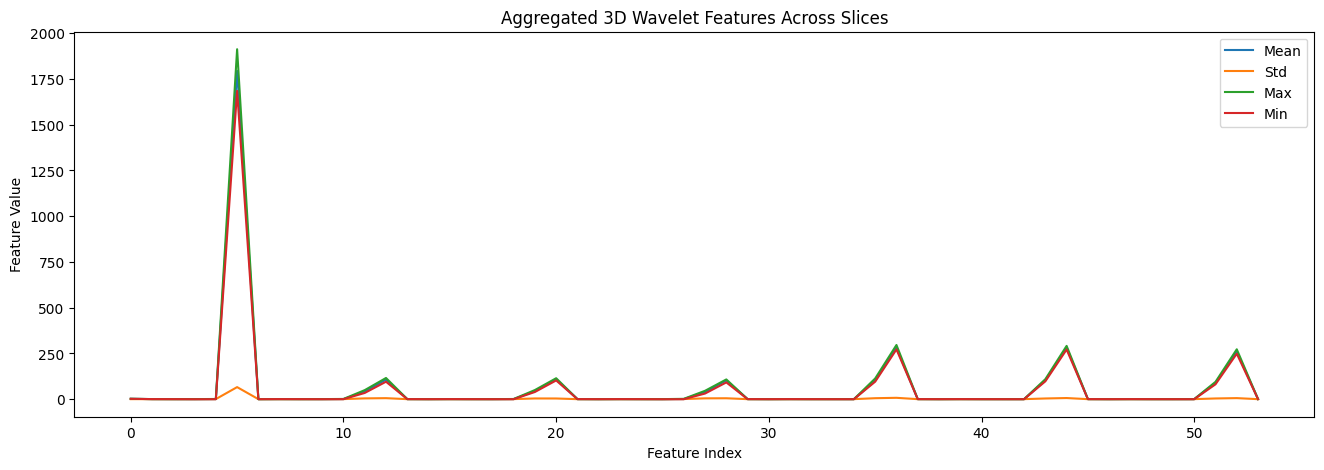

In [ ]:
import pywt
import numpy as np
import matplotlib.pyplot as plt

def extract_3d_wavelet_features(volume, wavelet='db4', level=2):
    """
    Extract features from 3D volumetric data using 3D wavelet transform
    Note: This requires pywt version that supports 3D transforms
    """
    try:
        # For 3D data, we might need to process slice by slice or use specialized libraries
        # This is a simplified example
        features = []
        
        # Process each 2D slice and aggregate features
        for slice_idx in range(volume.shape[2]):
            slice_2d = volume[:, :, slice_idx]
            slice_features, _ = extract_2d_wavelet_features(slice_2d, wavelet, level)
            features.append(slice_features)
        
        # Aggregate features across slices
        features = np.array(features)
        aggregated_features = [
            np.mean(features, axis=0),  # Mean across slices
            np.std(features, axis=0),   # Std across slices
            np.max(features, axis=0),   # Max across slices
            np.min(features, axis=0)    # Min across slices
        ]
        
        return np.concatenate(aggregated_features)
    
    except Exception as e:
        print(f"3D wavelet transform not available: {e}")
        return None

# Example with synthetic 3D data
np.random.seed(42)
synthetic_volume = np.random.random((64, 64, 10))  # 64x64 images, 10 slices
features_3d = extract_3d_wavelet_features(synthetic_volume)

if features_3d is not None:
    print(f"Extracted {len(features_3d)} 3D wavelet features")

# Assuming features_3d is the extracted 3D wavelet feature vector
n_2d_features = 54  # adjust if your 2D feature length differs
aggregated_features = features_3d.reshape(4, n_2d_features)  # mean, std, max, min

agg_names = ['Mean', 'Std', 'Max', 'Min']

plt.figure(figsize=(16, 5))
for i in range(4):
    plt.plot(aggregated_features[i], label=agg_names[i])
plt.title("Aggregated 3D Wavelet Features Across Slices")
plt.xlabel("Feature Index")
plt.ylabel("Feature Value")
plt.legend()
plt.savefig('./output/aggregated_3d_wavelet_features.png')
plt.show()


### 6.6.2 Multi-channel Signal Processing

Extracted 180 multi-channel features


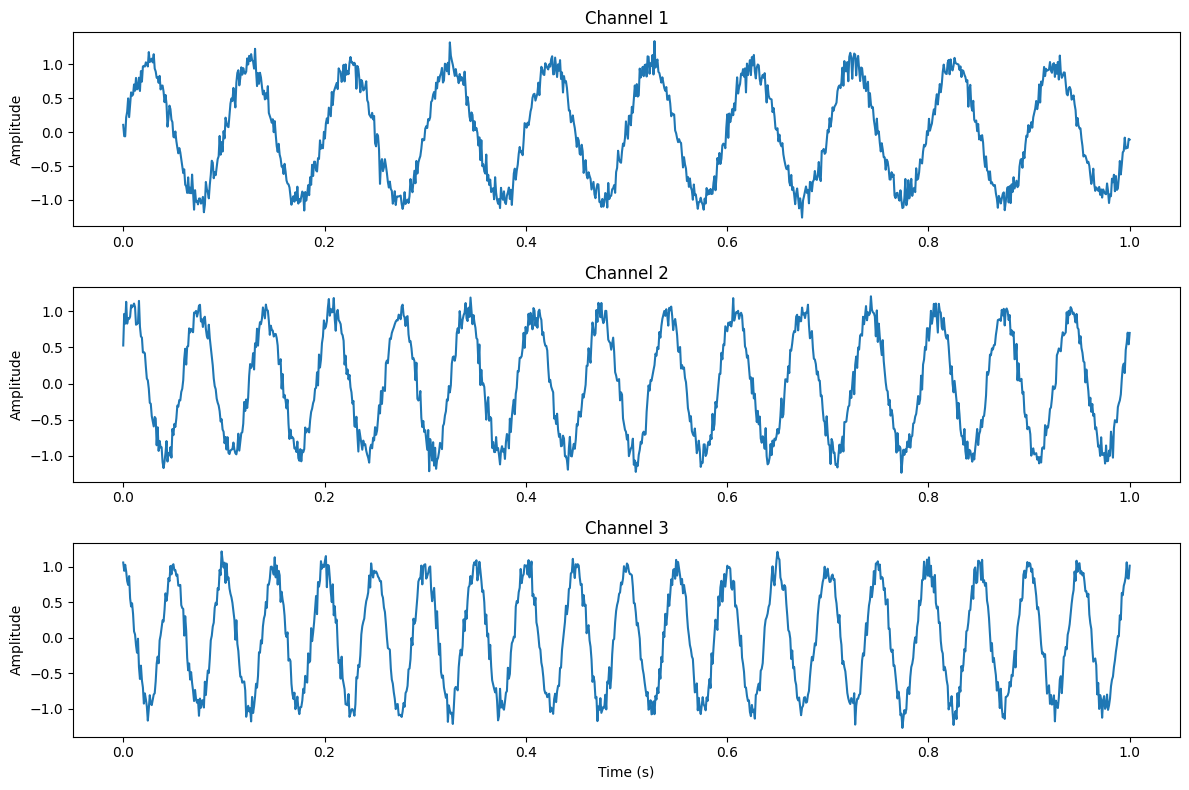

In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt

def multichannel_wavelet_features(multichannel_signal, wavelet='db4', level=4):
    """
    Extract features from multi-channel 1D signals
    multichannel_signal: array of shape (n_channels, n_samples)
    """
    n_channels, n_samples = multichannel_signal.shape
    
    # Features from individual channels
    all_features = []
    
    for ch in range(n_channels):
        ch_features, _ = comprehensive_wavelet_features(multichannel_signal[ch], wavelet, level)
        all_features.extend(ch_features)
    
    # Cross-channel features
    cross_features = []
    
    # Decompose all channels
    all_coeffs = [pywt.wavedec(multichannel_signal[ch], wavelet, level) 
                  for ch in range(n_channels)]
    
    # Compute cross-channel correlations at each decomposition level
    for level_idx in range(level + 1):
        level_coeffs = [coeffs[level_idx] for coeffs in all_coeffs]
        
        # Pairwise correlations between channels at this level
        for ch1 in range(n_channels):
            for ch2 in range(ch1 + 1, n_channels):
                # Ensure same length
                min_len = min(len(level_coeffs[ch1]), len(level_coeffs[ch2]))
                corr = np.corrcoef(level_coeffs[ch1][:min_len], 
                                 level_coeffs[ch2][:min_len])[0, 1]
                cross_features.append(corr if not np.isnan(corr) else 0)
    
    return np.concatenate([all_features, cross_features])

# Example with multi-channel synthetic data
n_channels, n_samples = 3, 1024
t = np.linspace(0, 1, n_samples)
multichannel_data = np.array([
    np.sin(2*np.pi*10*t) + 0.1*np.random.normal(size=n_samples),  # Channel 1
    np.sin(2*np.pi*15*t + np.pi/4) + 0.1*np.random.normal(size=n_samples),  # Channel 2
    np.sin(2*np.pi*20*t + np.pi/2) + 0.1*np.random.normal(size=n_samples)   # Channel 3
])

multichannel_features = multichannel_wavelet_features(multichannel_data)
print(f"Extracted {len(multichannel_features)} multi-channel features")

# Visualize multi-channel data
plt.figure(figsize=(12, 8))
for i in range(n_channels):
    plt.subplot(n_channels, 1, i+1)
    plt.plot(t, multichannel_data[i])
    plt.title(f'Channel {i+1}')
    plt.ylabel('Amplitude')
    if i == n_channels-1:
        plt.xlabel('Time (s)')
plt.tight_layout()
plt.savefig('./output/multichannel_signals.png')
plt.show()



## 6.7 Integration with Machine Learning Pipelines

### 6.7.1 Example: Classification with Wavelet Features

In [19]:
import pywt
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Synthetic dataset
np.random.seed(42)
signal = np.sin(np.linspace(0, 2*np.pi, 256))
X = np.array([wavelet_features(signal + np.random.normal(0, 0.1, 256), 'db4', 3) for _ in range(100)])
y = np.array([0]*50 + [1]*50)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train classifier
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.55


### 6.7.2 Complete ML Pipeline

Extracting wavelet features...
Dataset shape - Signals: (400, 512)
Raw features shape: (400, 7)
Wavelet features shape: (400, 55)

Random Forest (Wavelet):
Test Accuracy: 1.0000
CV Score: 1.0000 ± 0.0000

SVM (Wavelet):
Test Accuracy: 1.0000
CV Score: 1.0000 ± 0.0000

Neural Network (Wavelet):
Test Accuracy: 1.0000
CV Score: 1.0000 ± 0.0000

Random Forest (Raw):
Test Accuracy: 0.7250
CV Score: 0.7321 ± 0.0253


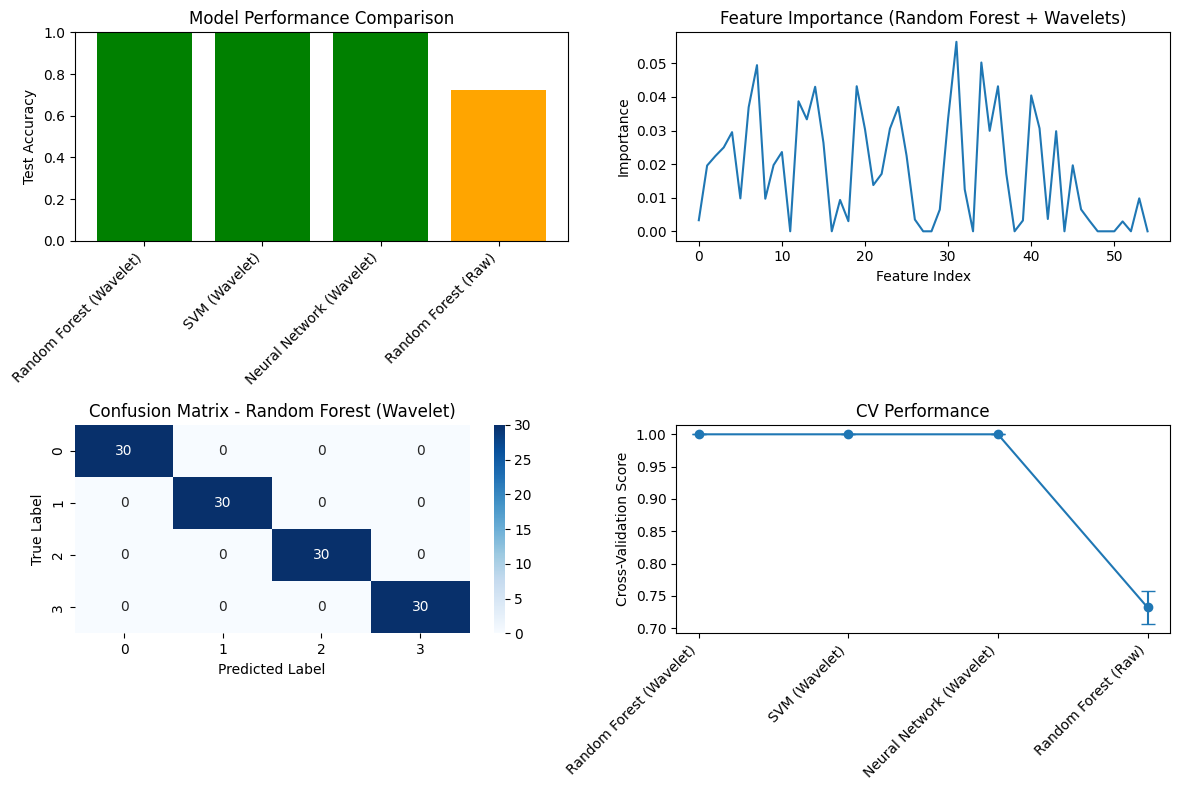

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
import seaborn as sns

# Generate synthetic dataset for demonstration
def generate_signal_dataset(n_samples=500, n_features=1024, noise_level=0.1):
    """Generate synthetic multi-class signal dataset"""
    np.random.seed(42)
    X = []
    y = []
    t = np.linspace(0, 1, n_features)
    
    for i in range(n_samples):
        # Create different signal types
        signal_type = i % 4
        
        if signal_type == 0:  # Low frequency sine
            signal = np.sin(2*np.pi*5*t) + noise_level*np.random.normal(size=n_features)
            label = 0
        elif signal_type == 1:  # High frequency sine
            signal = np.sin(2*np.pi*50*t) + noise_level*np.random.normal(size=n_features)
            label = 1
        elif signal_type == 2:  # Chirp signal
            freq = 10 + 40*t
            signal = np.sin(2*np.pi*freq*t) + noise_level*np.random.normal(size=n_features)
            label = 2
        else:  # Complex multi-component signal
            signal = (np.sin(2*np.pi*10*t) + 0.5*np.sin(2*np.pi*30*t) + 
                     0.3*np.sin(2*np.pi*100*t) + noise_level*np.random.normal(size=n_features))
            label = 3
        
        X.append(signal)
        y.append(label)
    
    return np.array(X), np.array(y)

# Generate dataset
X_signals, y_signals = generate_signal_dataset(n_samples=400, n_features=512)

# Extract wavelet features for all signals
print("Extracting wavelet features...")
X_wavelet = []
for signal in X_signals:
    features, _ = comprehensive_wavelet_features(signal, wavelet='db4', level=4)
    X_wavelet.append(features)
X_wavelet = np.array(X_wavelet)

# Also prepare raw signal features for comparison
X_raw = []
for signal in X_signals:
    raw_features = [
        np.mean(signal), np.std(signal), np.max(signal), np.min(signal),
        stats.skew(signal), stats.kurtosis(signal),
        np.sum(np.square(signal))  # Energy
    ]
    X_raw.append(raw_features)
X_raw = np.array(X_raw)

print(f"Dataset shape - Signals: {X_signals.shape}")
print(f"Raw features shape: {X_raw.shape}")
print(f"Wavelet features shape: {X_wavelet.shape}")

# Split data
X_train_wav, X_test_wav, y_train, y_test = train_test_split(
    X_wavelet, y_signals, test_size=0.3, random_state=42, stratify=y_signals)
X_train_raw, X_test_raw, _, _ = train_test_split(
    X_raw, y_signals, test_size=0.3, random_state=42, stratify=y_signals)

# Create pipelines with different classifiers
pipelines = {
    'Random Forest (Wavelet)': Pipeline([
        ('scaler', StandardScaler()),
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42))
    ]),
    'SVM (Wavelet)': Pipeline([
        ('scaler', StandardScaler()),
        ('svm', SVC(kernel='rbf', random_state=42))
    ]),
    'Neural Network (Wavelet)': Pipeline([
        ('scaler', StandardScaler()),
        ('nn', MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=500, random_state=42))
    ]),
    'Random Forest (Raw)': Pipeline([
        ('scaler', StandardScaler()),
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42))
    ])
}

# Train and evaluate models
results = {}
for name, pipeline in pipelines.items():
    if 'Raw' in name:
        X_train_curr, X_test_curr = X_train_raw, X_test_raw
    else:
        X_train_curr, X_test_curr = X_train_wav, X_test_wav
    
    # Train
    pipeline.fit(X_train_curr, y_train)
    
    # Predict
    y_pred = pipeline.predict(X_test_curr)
    
    # Evaluate
    accuracy = accuracy_score(y_test, y_pred)
    cv_scores = cross_val_score(pipeline, X_train_curr, y_train, cv=5)
    
    results[name] = {
        'accuracy': accuracy,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std(),
        'predictions': y_pred
    }
    
    print(f"\n{name}:")
    print(f"Test Accuracy: {accuracy:.4f}")
    print(f"CV Score: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

# Visualize results
plt.figure(figsize=(12, 8))

# Accuracy comparison
plt.subplot(2, 2, 1)
methods = list(results.keys())
accuracies = [results[method]['accuracy'] for method in methods]
colors = ['green' if 'Wavelet' in method else 'orange' for method in methods]
plt.bar(range(len(methods)), accuracies, color=colors)
plt.xticks(range(len(methods)), methods, rotation=45, ha='right')
plt.ylabel('Test Accuracy')
plt.title('Model Performance Comparison')
plt.ylim(0, 1)

# Feature importance for Random Forest with wavelets
rf_wavelet = pipelines['Random Forest (Wavelet)']['rf']
importances = rf_wavelet.feature_importances_

plt.subplot(2, 2, 2)
plt.plot(importances)
plt.title('Feature Importance (Random Forest + Wavelets)')
plt.xlabel('Feature Index')
plt.ylabel('Importance')

# Confusion matrix for best performing model
best_model = max(results.keys(), key=lambda k: results[k]['accuracy'])
best_predictions = results[best_model]['predictions']

plt.subplot(2, 2, 3)
cm = confusion_matrix(y_test, best_predictions)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f'Confusion Matrix - {best_model}')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')

# CV scores comparison
plt.subplot(2, 2, 4)
cv_means = [results[method]['cv_mean'] for method in methods]
cv_stds = [results[method]['cv_std'] for method in methods]
x_pos = range(len(methods))
plt.errorbar(x_pos, cv_means, yerr=cv_stds, fmt='o-', capsize=5)
plt.xticks(x_pos, methods, rotation=45, ha='right')
plt.ylabel('Cross-Validation Score')
plt.title('CV Performance')

plt.tight_layout()
plt.savefig('./output/model_performance_comparison.png')
plt.show()

## 6.8 Hyperparameter Tuning for Wavelet Features

In [27]:
import numpy as np
import pywt
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score

# --- Advanced 1D wavelet feature extraction ---
def advanced_wavelet_features(signal, wavelet='db4', level=4):
    coeffs = pywt.wavedec(signal, wavelet, level=level)
    features = []

    # Relative energy distribution
    total_energy = sum(np.sum(np.square(c)) for c in coeffs)
    rel_energy = [np.sum(np.square(c))/total_energy for c in coeffs]
    features.extend(rel_energy)

    # Cross-scale correlations (aligned)
    for i in range(len(coeffs)-1):
        finer = coeffs[i]
        coarser = coeffs[i+1]

        # Resize finer to match coarser
        min_len = min(len(finer), len(coarser))
        finer_resized = finer[:min_len]
        coarser_resized = coarser[:min_len]

        corr = np.corrcoef(finer_resized, coarser_resized)[0,1]
        features.append(0 if np.isnan(corr) else corr)

    # HF/LF ratio
    approx_energy = np.sum(np.square(coeffs[0]))
    detail_energy = sum(np.sum(np.square(c)) for c in coeffs[1:])
    hf_lf_ratio = detail_energy / approx_energy if approx_energy > 0 else 0
    features.append(hf_lf_ratio)

    return np.array(features)


# --- Custom transformer ---
class AdvancedWaveletTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, wavelet='db4', level=4):
        self.wavelet = wavelet
        self.level = level
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return np.array([advanced_wavelet_features(x, self.wavelet, self.level) for x in X])

# --- Clearly separable synthetic dataset ---
np.random.seed(42)
n_samples = 200
n_points = 512

# Class 0: sine with frequency 3, amplitude 1
X_class0 = [np.sin(np.linspace(0, 6*np.pi, n_points)) + np.random.normal(0, 0.05, n_points) for _ in range(n_samples//2)]
# Class 1: sine with frequency 6, amplitude 1.5
X_class1 = [1.5*np.sin(np.linspace(0, 12*np.pi, n_points)) + np.random.normal(0, 0.05, n_points) for _ in range(n_samples//2)]

X = np.array(X_class0 + X_class1)
y = np.array([0]*(n_samples//2) + [1]*(n_samples//2))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# --- Pipeline ---
pipeline = Pipeline([
    ('wavelet', AdvancedWaveletTransformer()),
    ('clf', RandomForestClassifier(random_state=42))
])

# --- Grid search ---
param_grid = {
    'wavelet__wavelet': ['db4', 'sym4', 'coif2'],
    'wavelet__level': [3,4,5],
    'clf__n_estimators': [100,200],
    'clf__max_depth': [None, 10, 20],
}

grid = GridSearchCV(pipeline, param_grid, cv=5, n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)

# --- Results ---
print("Best Parameters:", grid.best_params_)
print("Best CV Score:", grid.best_score_)

y_pred = grid.predict(X_test)
print("Test Accuracy:", accuracy_score(y_test, y_pred))


Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best Parameters: {'clf__max_depth': None, 'clf__n_estimators': 100, 'wavelet__level': 3, 'wavelet__wavelet': 'db4'}
Best CV Score: 1.0
Test Accuracy: 0.975


## 6.9 Case Studies and Applications

### 6.9.2 Emotion Recognition from EEG

a cleaner layout using only the 4 plots you actually generate, arranged in a 2×2 grid:

EEG dataset shape: (200, 14, 1024)
EEG Emotion Recognition - Random Forest: 1.0000
EEG Emotion Recognition - SVM: 0.9833
EEG Emotion Recognition - Neural Network: 1.0000


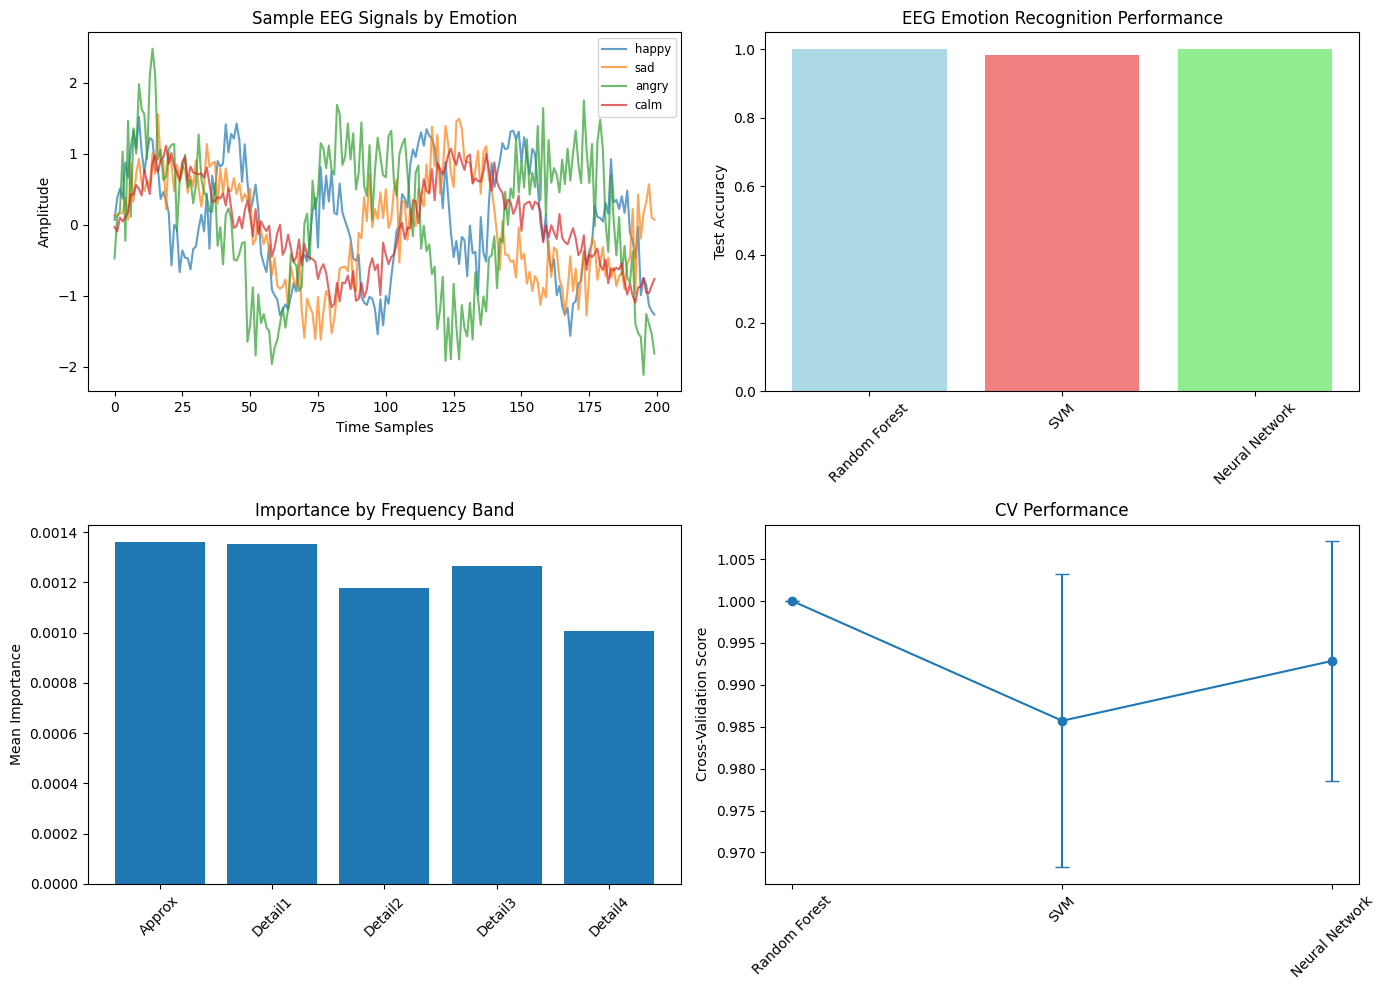

In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from scipy import stats

# Note: This example uses synthetic EEG data; in practice, use real datasets like DEAP or SEED
def simulate_eeg_data(n_samples=200, n_channels=14, n_samples_per_channel=1024):
    """
    Simulate multi-channel EEG data for different emotions
    """
    np.random.seed(42)
    emotions = ['happy', 'sad', 'angry', 'calm']
    X_eeg = []
    y_eeg = []
    
    t = np.linspace(0, 1, n_samples_per_channel)
    
    for i in range(n_samples):
        emotion_idx = i % 4
        emotion = emotions[emotion_idx]
        
        # Base alpha/beta waves
        alpha_freq = 8 + 4*np.random.random()  # 8-12 Hz
        beta_freq = 13 + 17*np.random.random()  # 13-30 Hz
        
        # Emotion-specific modifications
        if emotion == 'happy':
            signal = 1.0 * np.sin(2*np.pi*beta_freq*t) + 0.5 * np.sin(2*np.pi*alpha_freq*t)
            noise_level = 0.2
        elif emotion == 'sad':
            signal = 1.0 * np.sin(2*np.pi*alpha_freq*t) + 0.3 * np.sin(2*np.pi*beta_freq*t)
            noise_level = 0.3
        elif emotion == 'angry':
            signal = 1.2 * np.sin(2*np.pi*beta_freq*t) + 0.4 * np.sin(2*np.pi*30*t)  # Gamma burst
            noise_level = 0.4
        else:  # calm
            signal = 0.8 * np.sin(2*np.pi*alpha_freq*t) + 0.2 * np.sin(2*np.pi*beta_freq*t)
            noise_level = 0.1
        
        # Multi-channel with slight variations
        channels = []
        for ch in range(n_channels):
            channel_signal = signal + 0.1 * np.random.normal(size=n_samples_per_channel) * (ch/10 + 1)
            channel_signal += noise_level * np.random.normal(size=n_samples_per_channel)
            channels.append(channel_signal)
        
        X_eeg.append(np.array(channels))
        y_eeg.append(emotion_idx)
    
    return np.array(X_eeg), np.array(y_eeg), emotions

# Generate EEG data
X_eeg, y_eeg, emotion_names = simulate_eeg_data()
print(f"EEG dataset shape: {X_eeg.shape}")

# Extract features from multi-channel EEG
X_eeg_features = []
for sample in X_eeg:
    features = multichannel_wavelet_features(sample)
    X_eeg_features.append(features)
X_eeg_features = np.array(X_eeg_features)

# Train classifiers
X_train_eeg, X_test_eeg, y_train_eeg, y_test_eeg = train_test_split(
    X_eeg_features, y_eeg, test_size=0.3, random_state=42, stratify=y_eeg)

scaler_eeg = StandardScaler()
X_train_eeg_scaled = scaler_eeg.fit_transform(X_train_eeg)
X_test_eeg_scaled = scaler_eeg.transform(X_test_eeg)

eeg_classifiers = {
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
    'SVM': SVC(kernel='rbf', C=1, gamma='scale', random_state=42),
    'Neural Network': MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=500, random_state=42)
}

eeg_results = {}
for name, classifier in eeg_classifiers.items():
    classifier.fit(X_train_eeg_scaled, y_train_eeg)
    accuracy = classifier.score(X_test_eeg_scaled, y_test_eeg)
    cv_scores = cross_val_score(classifier, X_train_eeg_scaled, y_train_eeg, cv=5)
    
    eeg_results[name] = {
        'accuracy': accuracy,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std()
    }
    
    print(f"EEG Emotion Recognition - {name}: {accuracy:.4f}")

# Visualize EEG results

plt.figure(figsize=(14, 10))

# 1. Sample EEG signals for different emotions
plt.subplot(2, 2, 1)
for i, emotion in enumerate(emotion_names):
    sample_idx = np.where(y_eeg == i)[0][0]
    sample_channel = X_eeg[sample_idx, 0]  # First channel
    plt.plot(sample_channel[0:200], label=emotion, alpha=0.7)
plt.title('Sample EEG Signals by Emotion')
plt.xlabel('Time Samples')
plt.ylabel('Amplitude')
plt.legend(loc='upper right', fontsize='small')

# 2. Classifier performance (test accuracy)
plt.subplot(2, 2, 2)
methods = list(eeg_results.keys())
accuracies = [eeg_results[method]['accuracy'] for method in methods]
plt.bar(methods, accuracies, color=['lightblue', 'lightcoral', 'lightgreen'])
plt.ylabel('Test Accuracy')
plt.title('EEG Emotion Recognition Performance')
plt.xticks(rotation=45)

# 3. Random Forest feature importance by frequency band
if 'Random Forest' in eeg_results:
    plt.subplot(2, 2, 3)
    rf_eeg = eeg_classifiers['Random Forest']
    importances = rf_eeg.feature_importances_
    
    n_channels = 14
    n_stats_per_band = 11
    n_bands = 5  # A4, D4, D3, D2, D1
    
    band_importances = []
    for band in range(n_bands):
        start_idx = band * n_channels * n_stats_per_band
        end_idx = start_idx + n_channels * n_stats_per_band
        if end_idx <= len(importances):
            band_imp = np.mean(importances[start_idx:end_idx])
            band_importances.append(band_imp)
    
    if band_importances:
        band_names = ['Approx', 'Detail1', 'Detail2', 'Detail3', 'Detail4'][:len(band_importances)]
        plt.bar(band_names, band_importances)
        plt.title('Importance by Frequency Band')
        plt.ylabel('Mean Importance')
        plt.xticks(rotation=45)

# 4. Cross-validation comparison
plt.subplot(2, 2, 4)
cv_means = [eeg_results[method]['cv_mean'] for method in methods]
cv_stds = [eeg_results[method]['cv_std'] for method in methods]
plt.errorbar(range(len(methods)), cv_means, yerr=cv_stds, fmt='o-', capsize=5)
plt.xticks(range(len(methods)), methods, rotation=45)
plt.ylabel('Cross-Validation Score')
plt.title('CV Performance')

plt.tight_layout()
plt.savefig('./output/eeg_emotion_recognition_summary.png')
plt.show()


### 6.9.3 Fault Detection in Machinery

Machinery dataset shape: (300, 2048)
Conditions: ['normal', 'bearing_fault', 'gear_fault', 'imbalance']


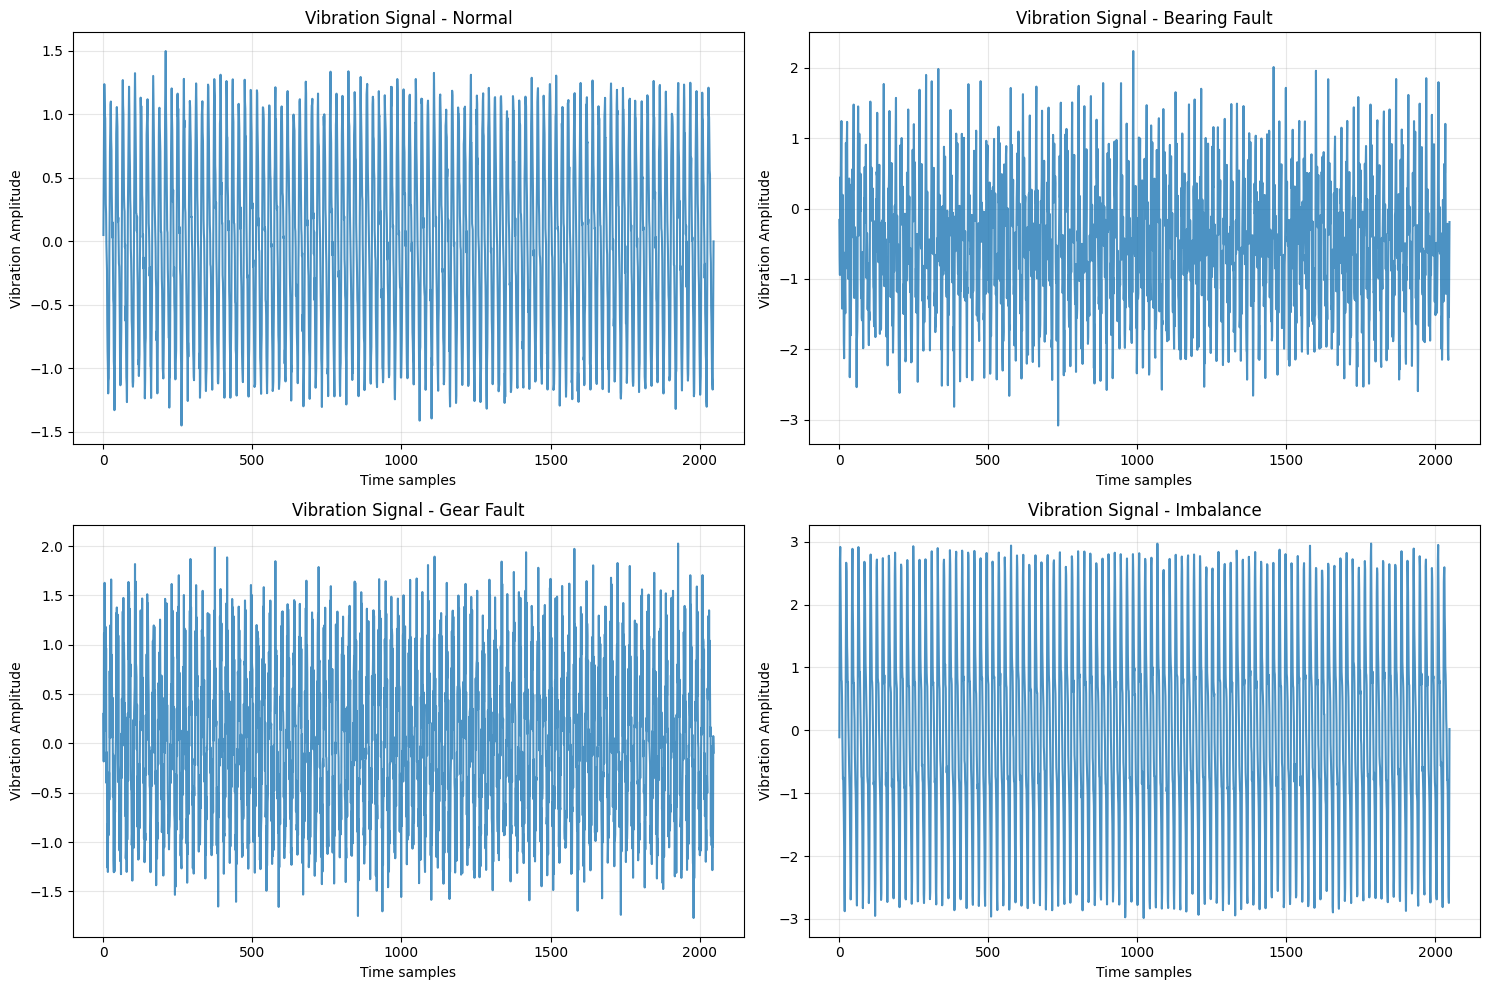

Extracting machinery wavelet features...
Machinery wavelet features shape: (300, 78)
Machinery Fault Detection - Random Forest: 1.0000 (CV: 1.0000±0.0000)
Machinery Fault Detection - SVM: 1.0000 (CV: 1.0000±0.0000)
Machinery Fault Detection - Gradient Boosting: 1.0000 (CV: 1.0000±0.0000)
Machinery Fault Detection - Logistic Regression: 1.0000 (CV: 1.0000±0.0000)

Detailed Results for Random Forest:
Classification Report:
               precision    recall  f1-score   support

       normal       1.00      1.00      1.00        23
bearing_fault       1.00      1.00      1.00        22
   gear_fault       1.00      1.00      1.00        23
    imbalance       1.00      1.00      1.00        22

     accuracy                           1.00        90
    macro avg       1.00      1.00      1.00        90
 weighted avg       1.00      1.00      1.00        90



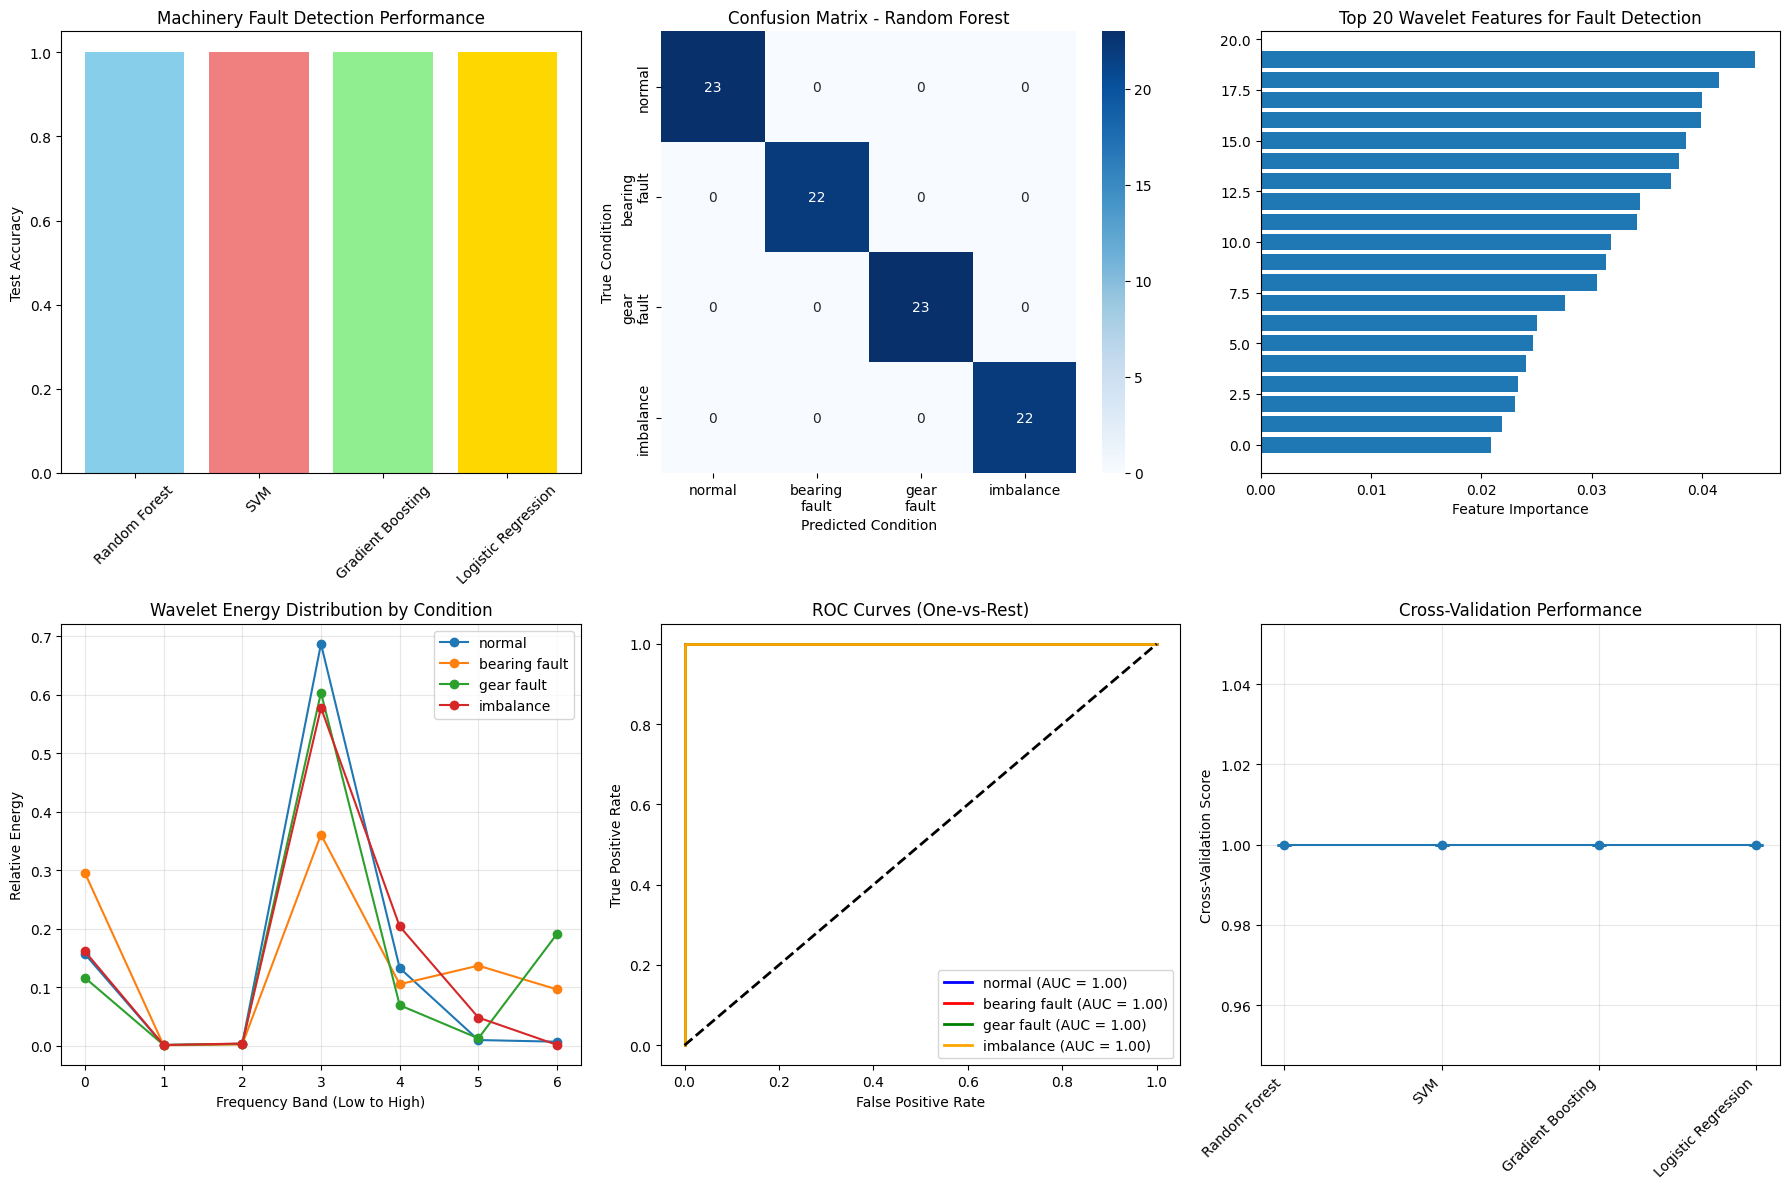

In [ ]:
def simulate_machinery_data():
    """
    Simulate vibration signals from machinery with different fault conditions
    """
    np.random.seed(42)
    conditions = ['normal', 'bearing_fault', 'gear_fault', 'imbalance']
    n_samples_per_condition = 75
    sequence_length = 2048  # Higher resolution for machinery signals
    
    X_machinery = []
    y_machinery = []
    
    t = np.linspace(0, 4, sequence_length)  # 4 seconds of data
    
    for condition_idx, condition in enumerate(conditions):
        for sample in range(n_samples_per_condition):
            if condition == 'normal':
                # Smooth operation with low-frequency components
                signal = (1.0*np.sin(2*np.pi*25*t) +  # Main rotation frequency
                         0.3*np.sin(2*np.pi*50*t) +   # Second harmonic
                         0.1*np.random.normal(size=sequence_length))  # Background noise
                
            elif condition == 'bearing_fault':
                # High-frequency impulses at bearing fault frequency
                signal = 1.0*np.sin(2*np.pi*25*t) + 0.3*np.sin(2*np.pi*50*t)
                # Add impulses at bearing fault frequency (e.g., 137 Hz)
                impulse_freq = 137
                impulse_times = np.arange(0, 4, 1/impulse_freq)
                for imp_time in impulse_times:
                    if imp_time < 4:
                        idx = int(imp_time * sequence_length / 4)
                        if idx < sequence_length:
                            # Damped impulse
                            impulse_duration = min(50, sequence_length - idx)
                            decay = np.exp(-np.arange(impulse_duration) * 0.1)
                            signal[idx:idx+impulse_duration] += 2.0 * decay * np.sin(2*np.pi*3000*np.arange(impulse_duration)/sequence_length*4)
                signal += 0.2*np.random.normal(size=sequence_length)
                
            elif condition == 'gear_fault':
                # Gear mesh frequency modulation
                gear_freq = 300  # Gear mesh frequency
                signal = (1.0*np.sin(2*np.pi*25*t) +
                         0.5*np.sin(2*np.pi*gear_freq*t) * (1 + 0.3*np.sin(2*np.pi*25*t)) +  # Amplitude modulation
                         0.2*np.random.normal(size=sequence_length))
                
            else:  # imbalance
                # Strong harmonic components at rotation frequency and harmonics
                signal = (2.0*np.sin(2*np.pi*25*t) +  # Increased fundamental
                         1.0*np.sin(2*np.pi*50*t) +   # Strong second harmonic
                         0.5*np.sin(2*np.pi*75*t) +   # Third harmonic
                         0.1*np.random.normal(size=sequence_length))
            
            X_machinery.append(signal)
            y_machinery.append(condition_idx)
    
    return np.array(X_machinery), np.array(y_machinery), conditions

# Generate machinery data
X_machinery, y_machinery, condition_names = simulate_machinery_data()
print(f"Machinery dataset shape: {X_machinery.shape}")
print(f"Conditions: {condition_names}")

# Visualize machinery signals
plt.figure(figsize=(15, 10))
for i, condition in enumerate(condition_names):
    plt.subplot(2, 2, i+1)
    condition_samples = X_machinery[y_machinery == i]
    sample_signal = condition_samples[0]
    
    plt.plot(sample_signal, alpha=0.8)
    plt.title(f'Vibration Signal - {condition.replace("_", " ").title()}')
    plt.xlabel('Time samples')
    plt.ylabel('Vibration Amplitude')
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('./output/machinery_signals.png')
plt.show()

# Extract advanced wavelet features for fault detection
def extract_machinery_wavelet_features(signal, wavelet='db8', level=6):
    """
    Extract specialized wavelet features for machinery fault detection
    """
    # Use higher-order wavelet for better frequency resolution
    coeffs = pywt.wavedec(signal, wavelet, level=level)
    
    features = []
    
    # Standard statistical features for each band
    for i, c in enumerate(coeffs):
        band_features = [
            np.mean(c), np.std(c), np.var(c),
            stats.skew(c), stats.kurtosis(c),
            np.sum(np.square(c)),  # Energy
            np.sqrt(np.mean(np.square(c))),  # RMS
        ]
        
        # Additional fault-specific features
        # Peak factor (Crest factor)
        if np.std(c) > 1e-10:
            crest_factor = np.max(np.abs(c)) / np.sqrt(np.mean(np.square(c)))
            band_features.append(crest_factor)
        else:
            band_features.append(0)
        
        # Shape factor
        mean_abs = np.mean(np.abs(c))
        if mean_abs > 1e-10:
            shape_factor = np.sqrt(np.mean(np.square(c))) / mean_abs
            band_features.append(shape_factor)
        else:
            band_features.append(0)
        
        # Impulse factor
        max_abs = np.max(np.abs(c))
        if mean_abs > 1e-10:
            impulse_factor = max_abs / mean_abs
            band_features.append(impulse_factor)
        else:
            band_features.append(0)
        
        features.extend(band_features)
    
    # Relative energy distribution (important for fault detection)
    total_energy = sum(np.sum(np.square(c)) for c in coeffs)
    for c in coeffs:
        relative_energy = np.sum(np.square(c)) / (total_energy + 1e-12)
        features.append(relative_energy)
    
    # Energy ratios between frequency bands
    high_freq_energy = sum(np.sum(np.square(coeffs[i])) for i in range(1, min(4, len(coeffs))))
    low_freq_energy = np.sum(np.square(coeffs[0])) + sum(np.sum(np.square(coeffs[i])) for i in range(4, len(coeffs)))
    
    if low_freq_energy > 1e-12:
        hf_lf_ratio = high_freq_energy / low_freq_energy
        features.append(hf_lf_ratio)
    else:
        features.append(0)
    
    return np.array(features)

print("Extracting machinery wavelet features...")
X_machinery_features = []
for signal in X_machinery:
    features = extract_machinery_wavelet_features(signal)
    X_machinery_features.append(features)
X_machinery_features = np.array(X_machinery_features)

print(f"Machinery wavelet features shape: {X_machinery_features.shape}")

# Train fault detection classifiers
X_train_mach, X_test_mach, y_train_mach, y_test_mach = train_test_split(
    X_machinery_features, y_machinery, test_size=0.3, random_state=42, stratify=y_machinery)

scaler_mach = StandardScaler()
X_train_mach_scaled = scaler_mach.fit_transform(X_train_mach)
X_test_mach_scaled = scaler_mach.transform(X_test_mach)

# Test multiple classifiers
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

machinery_classifiers = {
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42),
    'SVM': SVC(kernel='rbf', C=10, gamma='scale', random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=200, random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42)
}

machinery_results = {}
for name, classifier in machinery_classifiers.items():
    classifier.fit(X_train_mach_scaled, y_train_mach)
    accuracy = classifier.score(X_test_mach_scaled, y_test_mach)
    cv_scores = cross_val_score(classifier, X_train_mach_scaled, y_train_mach, cv=5)
    
    machinery_results[name] = {
        'accuracy': accuracy,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std(),
        'classifier': classifier
    }
    
    print(f"Machinery Fault Detection - {name}: {accuracy:.4f} (CV: {cv_scores.mean():.4f}±{cv_scores.std():.4f})")

# Get best classifier for detailed analysis
best_mach_classifier_name = max(machinery_results.keys(), 
                                key=lambda k: machinery_results[k]['accuracy'])
best_mach_classifier = machinery_results[best_mach_classifier_name]['classifier']

# Detailed evaluation
y_pred_mach = best_mach_classifier.predict(X_test_mach_scaled)

print(f"\nDetailed Results for {best_mach_classifier_name}:")
print("Classification Report:")
print(classification_report(y_test_mach, y_pred_mach, target_names=condition_names))

# Visualize machinery fault detection results
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Classifier performance comparison
axes[0, 0].bar(machinery_results.keys(), 
               [r['accuracy'] for r in machinery_results.values()],
               color=['skyblue', 'lightcoral', 'lightgreen', 'gold'])
axes[0, 0].set_ylabel('Test Accuracy')
axes[0, 0].set_title('Machinery Fault Detection Performance')
axes[0, 0].tick_params(axis='x', rotation=45)

# Confusion matrix
cm_mach = confusion_matrix(y_test_mach, y_pred_mach)
sns.heatmap(cm_mach, annot=True, fmt='d', cmap='Blues',
            xticklabels=[name.replace('_', '\n') for name in condition_names],
            yticklabels=[name.replace('_', '\n') for name in condition_names],
            ax=axes[0, 1])
axes[0, 1].set_title(f'Confusion Matrix - {best_mach_classifier_name}')
axes[0, 1].set_ylabel('True Condition')
axes[0, 1].set_xlabel('Predicted Condition')

# Feature importance (for tree-based classifiers)
if hasattr(best_mach_classifier, 'feature_importances_'):
    importances = best_mach_classifier.feature_importances_
    top_indices = np.argsort(importances)[-20:]
    
    axes[0, 2].barh(range(len(top_indices)), importances[top_indices])
    axes[0, 2].set_xlabel('Feature Importance')
    axes[0, 2].set_title('Top 20 Wavelet Features for Fault Detection')

# Frequency analysis of different conditions
axes[1, 0].set_title('Wavelet Energy Distribution by Condition')
for i, condition in enumerate(condition_names):
    condition_features = X_machinery_features[y_machinery == i]
    # Extract relative energy features (last 7 features before energy ratio)
    energy_features = condition_features[:, -8:-1]  # Last 7 relative energy features
    mean_energies = np.mean(energy_features, axis=0)
    
    axes[1, 0].plot(mean_energies, label=condition.replace('_', ' '), marker='o')

axes[1, 0].set_xlabel('Frequency Band (Low to High)')
axes[1, 0].set_ylabel('Relative Energy')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# ROC curves for binary classification (Normal vs Faulty)
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.multiclass import OneVsRestClassifier

# Binarize labels for ROC analysis
y_test_bin = label_binarize(y_test_mach, classes=range(len(condition_names)))
y_score = best_mach_classifier.predict_proba(X_test_mach_scaled) if hasattr(best_mach_classifier, 'predict_proba') else None

if y_score is not None:
    axes[1, 1].set_title('ROC Curves (One-vs-Rest)')
    colors = ['blue', 'red', 'green', 'orange']
    for i, (condition, color) in enumerate(zip(condition_names, colors)):
        if i < y_test_bin.shape[1]:
            fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
            roc_auc = auc(fpr, tpr)
            axes[1, 1].plot(fpr, tpr, color=color, lw=2,
                           label=f'{condition.replace("_", " ")} (AUC = {roc_auc:.2f})')
    
    axes[1, 1].plot([0, 1], [0, 1], 'k--', lw=2)
    axes[1, 1].set_xlabel('False Positive Rate')
    axes[1, 1].set_ylabel('True Positive Rate')
    axes[1, 1].legend(loc='lower right')
else:
    axes[1, 1].text(0.5, 0.5, 'ROC curves not available\n(classifier does not support probabilities)',
                    ha='center', va='center', transform=axes[1, 1].transAxes)
    axes[1, 1].set_title('ROC Analysis')

# Cross-validation scores
axes[1, 2].set_title('Cross-Validation Performance')
cv_means = [machinery_results[method]['cv_mean'] for method in machinery_results.keys()]
cv_stds = [machinery_results[method]['cv_std'] for method in machinery_results.keys()]
x_pos = range(len(machinery_results))

axes[1, 2].errorbar(x_pos, cv_means, yerr=cv_stds, fmt='o-', capsize=5, capthick=2)
axes[1, 2].set_xticks(x_pos)
axes[1, 2].set_xticklabels(machinery_results.keys(), rotation=45, ha='right')
axes[1, 2].set_ylabel('Cross-Validation Score')
axes[1, 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('./output/machinery_fault_detection_summary.png')
plt.show()

## 6.10 Dimensionality Reduction Techniques

Here's an enhanced version of your PCA visualization that includes multiple classes with distinct colors and explained variance information:

Explained variance ratio: [0.51951836 0.13809369 0.12034771]


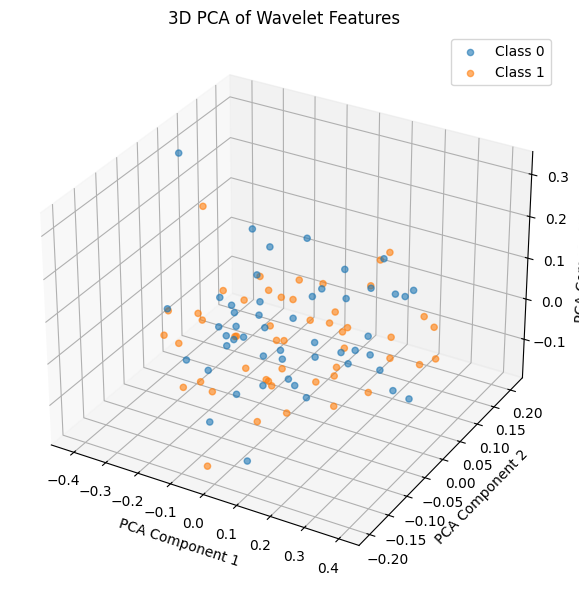

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# Synthetic wavelet features (example)
X = np.array([wavelet_features(signal + np.random.normal(0, 0.1, 2048), 'db4', 3) for _ in range(100)])
y = np.array([0]*50 + [1]*50)

# Apply PCA with 3 components
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X)

print("Explained variance ratio:", pca.explained_variance_ratio_)

# 3D Scatter Plot
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X_pca[y==0, 0], X_pca[y==0, 1], X_pca[y==0, 2], label='Class 0', alpha=0.6)
ax.scatter(X_pca[y==1, 0], X_pca[y==1, 1], X_pca[y==1, 2], label='Class 1', alpha=0.6)

ax.set_xlabel('PCA Component 1')
ax.set_ylabel('PCA Component 2')
ax.set_zlabel('PCA Component 3')
ax.set_title('3D PCA of Wavelet Features')
ax.legend()
plt.tight_layout()
plt.savefig('./output/3d_pca_wavelet_features.png')
plt.show()


## 6.11 Optimization and Best Practices

### 6.11.1 Wavelet Selection and Parameter Tuning

Comparing different wavelets and decomposition levels...

Wavelet Comparison Results:
Wavelet_Level	Mean CV	Std CV	Features
---------------------------------------------
db4_L3      	1.0000	0.0000	44
db4_L4      	1.0000	0.0000	55
db4_L5      	1.0000	0.0000	66
db4_L6      	1.0000	0.0000	77
db8_L3      	1.0000	0.0000	44
db8_L4      	1.0000	0.0000	55
db8_L5      	1.0000	0.0000	66
db8_L6      	1.0000	0.0000	77
haar_L3     	1.0000	0.0000	44
haar_L4     	1.0000	0.0000	55
haar_L5     	1.0000	0.0000	66
haar_L6     	1.0000	0.0000	77
coif2_L3    	1.0000	0.0000	44
coif2_L4    	1.0000	0.0000	55
coif2_L5    	1.0000	0.0000	66
coif2_L6    	1.0000	0.0000	77
bior2.2_L3  	1.0000	0.0000	44
bior2.2_L4  	1.0000	0.0000	55
bior2.2_L5  	1.0000	0.0000	66
bior2.2_L6  	1.0000	0.0000	77


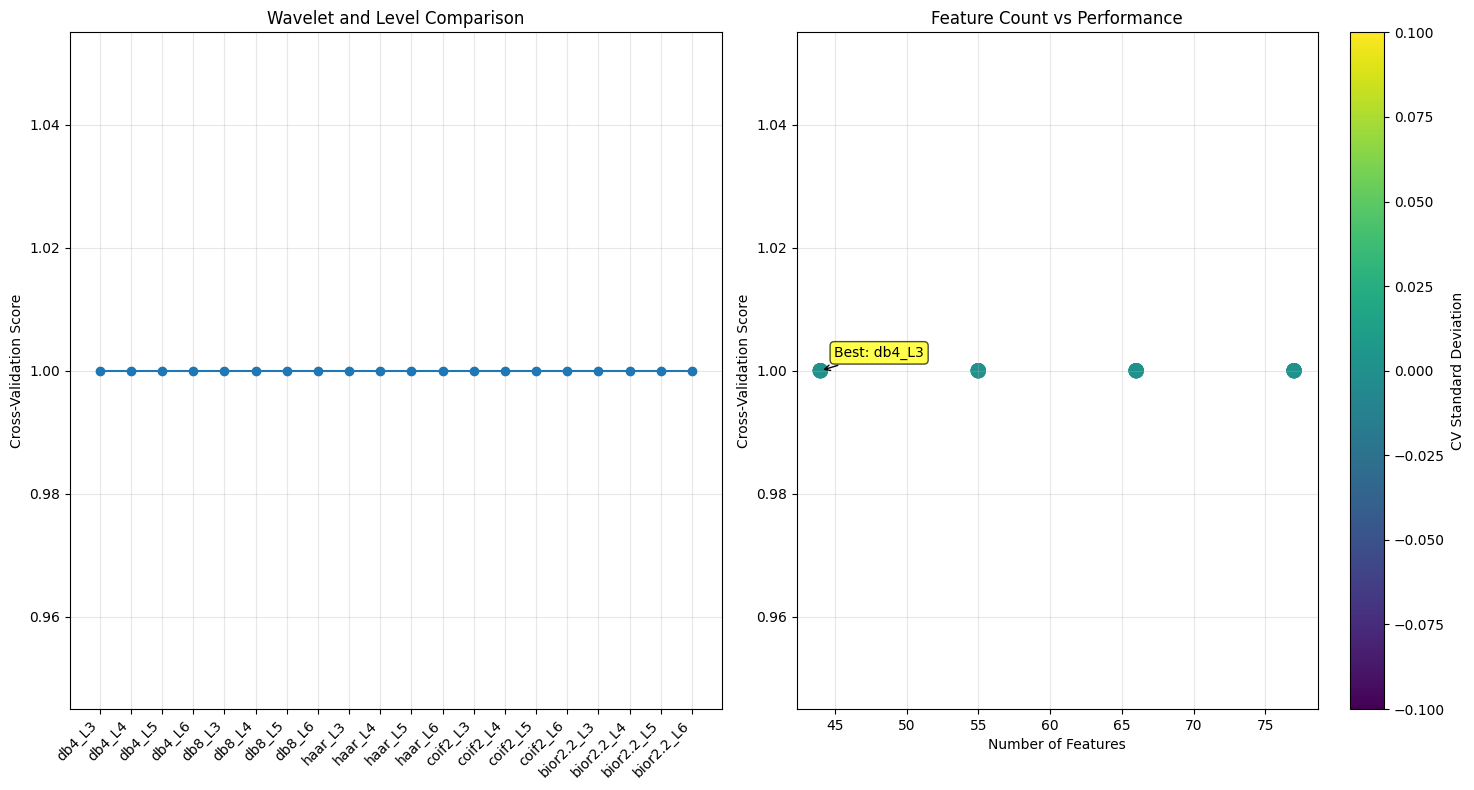


Best configuration: db4_L3
Performance: 1.0000 ± 0.0000


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pywt
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

import warnings
warnings.filterwarnings('ignore')

def compare_wavelets_performance(X, y, wavelets=['db4', 'db8', 'haar', 'coif2', 'bior2.2'], 
                                levels=[3, 4, 5, 6]):
    """
    Compare performance of different wavelets and decomposition levels
    """
    from sklearn.model_selection import cross_val_score
    
    results = {}
    
    for wavelet in wavelets:
        for level in levels:
            try:
                # Extract features with current wavelet and level
                X_features = []
                for signal in X:
                    features, _ = comprehensive_wavelet_features(signal, wavelet, level)
                    X_features.append(features)
                X_features = np.array(X_features)
                
                # Train classifier and get CV score
                scaler = StandardScaler()
                X_scaled = scaler.fit_transform(X_features)
                
                rf = RandomForestClassifier(n_estimators=100, random_state=42)
                cv_scores = cross_val_score(rf, X_scaled, y, cv=5)
                
                results[f"{wavelet}_L{level}"] = {
                    'mean': cv_scores.mean(),
                    'std': cv_scores.std(),
                    'wavelet': wavelet,
                    'level': level,
                    'n_features': X_features.shape[1]
                }
                
            except Exception as e:
                print(f"Error with {wavelet}, level {level}: {e}")
    
    return results

# Compare wavelets on synthetic data
print("Comparing different wavelets and decomposition levels...")
wavelet_comparison = compare_wavelets_performance(X_signals[:100], y_signals[:100])  # Use subset for speed

# Display results
print("\nWavelet Comparison Results:")
print("Wavelet_Level\tMean CV\tStd CV\tFeatures")
print("-" * 45)
for config, result in sorted(wavelet_comparison.items(), 
                           key=lambda x: x[1]['mean'], reverse=True):
    print(f"{config:12s}\t{result['mean']:.4f}\t{result['std']:.4f}\t{result['n_features']}")

# Visualize wavelet comparison
plt.figure(figsize=(15, 8))

# Performance comparison
plt.subplot(1, 2, 1)
configs = list(wavelet_comparison.keys())
means = [wavelet_comparison[config]['mean'] for config in configs]
stds = [wavelet_comparison[config]['std'] for config in configs]

x_pos = range(len(configs))
plt.errorbar(x_pos, means, yerr=stds, fmt='o-', capsize=3)
plt.xticks(x_pos, configs, rotation=45, ha='right')
plt.ylabel('Cross-Validation Score')
plt.title('Wavelet and Level Comparison')
plt.grid(True, alpha=0.3)

# Feature count vs performance
plt.subplot(1, 2, 2)
n_features = [wavelet_comparison[config]['n_features'] for config in configs]
plt.scatter(n_features, means, c=stds, cmap='viridis', s=100)
plt.colorbar(label='CV Standard Deviation')
plt.xlabel('Number of Features')
plt.ylabel('Cross-Validation Score')
plt.title('Feature Count vs Performance')
plt.grid(True, alpha=0.3)

# Annotate best points
best_config = max(wavelet_comparison.keys(), key=lambda x: wavelet_comparison[x]['mean'])
best_idx = configs.index(best_config)
plt.annotate(f'Best: {best_config}', 
            (n_features[best_idx], means[best_idx]),
            xytext=(10, 10), textcoords='offset points',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
            arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0'))

plt.tight_layout()
plt.savefig('./output/wavelet_comparison.png')
plt.show()

print(f"\nBest configuration: {best_config}")
print(f"Performance: {wavelet_comparison[best_config]['mean']:.4f} ± {wavelet_comparison[best_config]['std']:.4f}")

### 6.11.2 Computational Optimization

In [44]:
import numpy as np
from concurrent.futures import ThreadPoolExecutor
from functools import partial
import time

# Make sure this function is top-level (not nested)
def extract_single_signal_features(signal, wavelet='db4', level=4):
    """
    Extract wavelet features for a single signal
    """
    features, _ = comprehensive_wavelet_features(signal, wavelet, level)
    return features

def optimized_feature_extraction(signals, wavelet='db4', level=4, n_jobs=4):
    """
    Optimized parallel feature extraction using threads (Windows-safe)
    """
    start_time = time.time()
    
    if n_jobs == 1:
        # Sequential
        features = [extract_single_signal_features(signal, wavelet, level) for signal in signals]
    else:
        # Thread-based parallelism
        func = partial(extract_single_signal_features, wavelet=wavelet, level=level)
        with ThreadPoolExecutor(max_workers=n_jobs) as executor:
            features = list(executor.map(func, signals))
    
    end_time = time.time()
    processing_time = end_time - start_time
    
    return np.array(features), processing_time

# ------------------------
# Example usage (Windows-safe)
if __name__ == "__main__":
    test_signals = X_signals[:100]  # Use a subset for benchmarking
    features, time_taken = optimized_feature_extraction(test_signals, n_jobs=4)
    print(f"Processed {len(test_signals)} signals in {time_taken:.2f}s")
    print(f"Extracted features shape: {features.shape}")


Processed 100 signals in 0.56s
Extracted features shape: (100, 55)


### 6.11.3 Feature Selection and Validation Strategies

Performing comprehensive feature validation...

Validation Results:
Test Accuracy: 1.0000
CV Score: 1.0000 ± 0.0000
Highly correlated feature pairs: 7
Unstable important features: 0


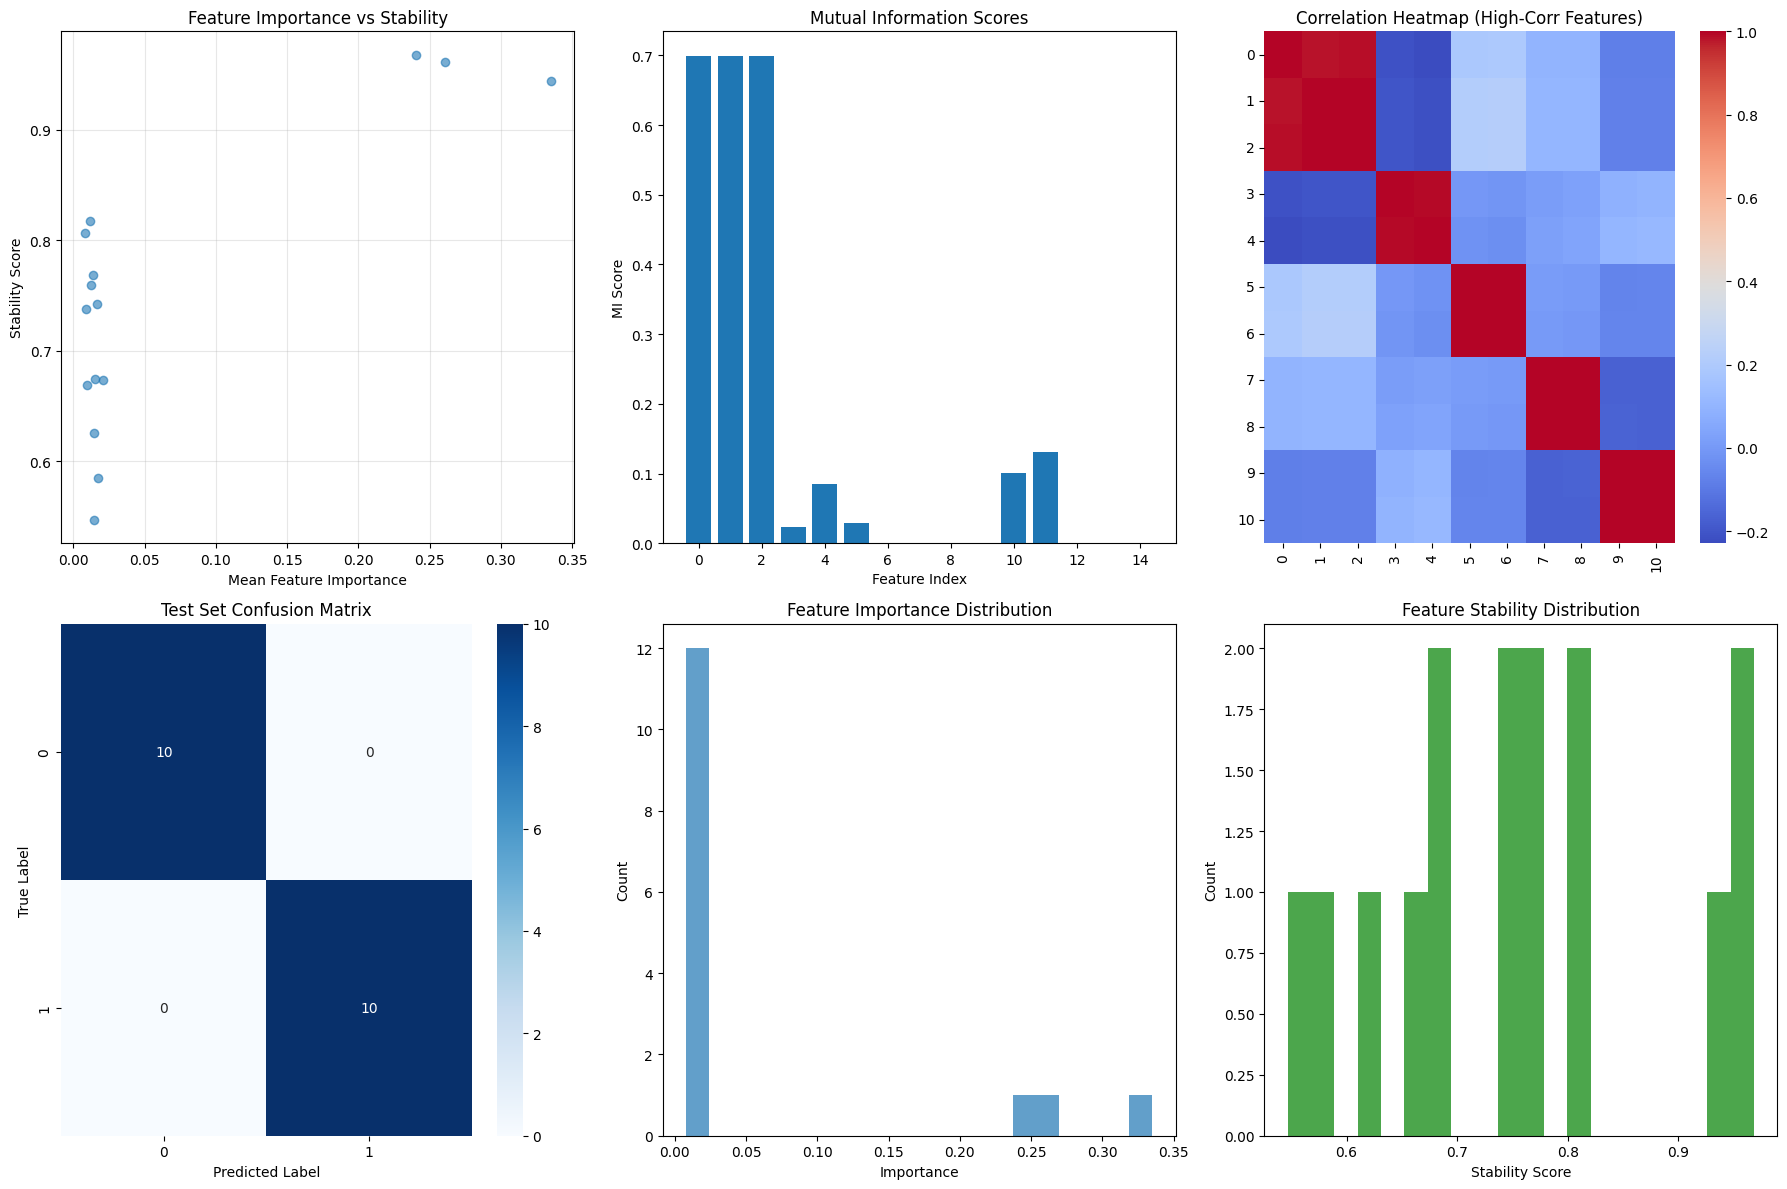

In [ ]:
def comprehensive_feature_validation(X_features, y, test_size=0.2, cv_folds=5):
    """
    Comprehensive validation including stability and interpretability analysis
    """
    from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score
    from sklearn.feature_selection import mutual_info_classif
    from sklearn.metrics import classification_report, accuracy_score
    from sklearn.preprocessing import StandardScaler
    from sklearn.ensemble import RandomForestClassifier
    import numpy as np

    results = {}
    
    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        X_features, y, test_size=test_size, random_state=42, stratify=y)
    
    # Scale features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # 1. Stability analysis - feature importance consistency across folds
    skf = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=42)
    feature_importances = []
    
    for train_idx, val_idx in skf.split(X_train_scaled, y_train):
        X_fold_train, X_fold_val = X_train_scaled[train_idx], X_train_scaled[val_idx]
        y_fold_train, y_fold_val = y_train[train_idx], y_train[val_idx]
        
        rf = RandomForestClassifier(n_estimators=100, random_state=42)
        rf.fit(X_fold_train, y_fold_train)
        feature_importances.append(rf.feature_importances_)
    
    feature_importances = np.array(feature_importances)
    importance_mean = np.mean(feature_importances, axis=0)
    importance_std = np.std(feature_importances, axis=0)
    
    # Calculate stability (1 - coefficient of variation)
    stability_scores = 1 - (importance_std / (importance_mean + 1e-10))
    
    results['feature_stability'] = {
        'mean_importance': importance_mean,
        'importance_std': importance_std,
        'stability_scores': stability_scores
    }
    
    # 2. Mutual information analysis
    mi_scores = mutual_info_classif(X_train_scaled, y_train, random_state=42)
    results['mutual_info'] = mi_scores
    
    # 3. Correlation analysis
    feature_corr = np.corrcoef(X_train_scaled.T)
    # Find highly correlated feature pairs
    high_corr_pairs = []
    for i in range(len(feature_corr)):
        for j in range(i+1, len(feature_corr)):
            if abs(feature_corr[i, j]) > 0.8:
                high_corr_pairs.append((i, j, feature_corr[i, j]))
    
    results['high_correlations'] = high_corr_pairs
    results['feature_corr'] = feature_corr  # Add feature_corr to results
    
    # 4. Final model evaluation
    rf_final = RandomForestClassifier(n_estimators=200, random_state=42)
    rf_final.fit(X_train_scaled, y_train)
    
    y_pred = rf_final.predict(X_test_scaled)
    test_accuracy = accuracy_score(y_test, y_pred)
    cv_scores = cross_val_score(rf_final, X_train_scaled, y_train, cv=cv_folds)
    
    results['model_performance'] = {
        'test_accuracy': test_accuracy,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std(),
        'classification_report': classification_report(y_test, y_pred),
        'y_pred': y_pred,  # Add y_pred to results for confusion matrix
        'y_test': y_test   # Add y_test to results for confusion matrix
    }
    
    return results

# Apply comprehensive validation to synthetic data
print("Performing comprehensive feature validation...")
validation_results = comprehensive_feature_validation(X_wavelet, y_signals)

print("\nValidation Results:")
print(f"Test Accuracy: {validation_results['model_performance']['test_accuracy']:.4f}")
print(f"CV Score: {validation_results['model_performance']['cv_mean']:.4f} ± {validation_results['model_performance']['cv_std']:.4f}")
print(f"Highly correlated feature pairs: {len(validation_results['high_correlations'])}")

# Visualize validation results
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Feature stability analysis
stability_scores = validation_results['feature_stability']['stability_scores']
mean_importance = validation_results['feature_stability']['mean_importance']

axes[0, 0].scatter(mean_importance, stability_scores, alpha=0.6)
axes[0, 0].set_xlabel('Mean Feature Importance')
axes[0, 0].set_ylabel('Stability Score')
axes[0, 0].set_title('Feature Importance vs Stability')
axes[0, 0].grid(True, alpha=0.3)

# Identify unstable but important features
unstable_important = np.where((mean_importance > np.percentile(mean_importance, 75)) & 
                             (stability_scores < np.percentile(stability_scores, 25)))[0]
print(f"Unstable important features: {len(unstable_important)}")

# Mutual information scores
mi_scores = validation_results['mutual_info']
axes[0, 1].bar(range(len(mi_scores)), mi_scores)
axes[0, 1].set_title('Mutual Information Scores')
axes[0, 1].set_xlabel('Feature Index')
axes[0, 1].set_ylabel('MI Score')

# Correlation heatmap for top correlated features
feature_corr = validation_results['feature_corr']  # Use feature_corr from results
if validation_results['high_correlations']:
    top_corr = sorted(validation_results['high_correlations'], key=lambda x: abs(x[2]), reverse=True)[:10]
    corr_indices = list(set([p[0] for p in top_corr] + [p[1] for p in top_corr]))
    if len(corr_indices) > 0:  # Ensure indices are valid
        corr_matrix = feature_corr[np.ix_(corr_indices, corr_indices)]
        sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', ax=axes[0, 2])
        axes[0, 2].set_title('Correlation Heatmap (High-Corr Features)')
        axes[0, 2].set_xticklabels(range(len(corr_indices)), rotation=90)
        axes[0, 2].set_yticklabels(range(len(corr_indices)), rotation=0)
else:
    axes[0, 2].text(0.5, 0.5, 'No high correlations', ha='center', va='center', transform=axes[0, 2].transAxes)
    axes[0, 2].set_title('No High Correlations')

# Test set confusion matrix
y_pred_val = validation_results['model_performance']['y_pred']  # Use actual y_pred
y_test_val = validation_results['model_performance']['y_test']  # Use actual y_test
cm_val = confusion_matrix(y_test_val, y_pred_val)
sns.heatmap(cm_val, annot=True, fmt='d', cmap='Blues', ax=axes[1, 0])
axes[1, 0].set_title('Test Set Confusion Matrix')
axes[1, 0].set_ylabel('True Label')
axes[1, 0].set_xlabel('Predicted Label')

# Feature importance distribution
axes[1, 1].hist(mean_importance, bins=20, alpha=0.7)
axes[1, 1].set_title('Feature Importance Distribution')
axes[1, 1].set_xlabel('Importance')
axes[1, 1].set_ylabel('Count')

# Stability score distribution
axes[1, 2].hist(stability_scores, bins=20, alpha=0.7, color='green')
axes[1, 2].set_title('Feature Stability Distribution')
axes[1, 2].set_xlabel('Stability Score')
axes[1, 2].set_ylabel('Count')

plt.tight_layout()
plt.savefig('./output/comprehensive_feature_validation.png')
plt.show()